[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/farrelrassya/Build-a-Large-Language-Model-From-Scratch/blob/main/05.Pretraining_On_Unlabeled_Data.ipynb)

# Chapter 5 -- Pretraining on Unlabeled Data

*Build a Large Language Model (From Scratch)* -- Sebastian Raschka (Manning, 2024)

**Technical edition -- setiap output di notebook ini dieksekusi riil di mesin builder; tidak ada output yang difabrikasi.**

Bab ini mengubah `GPTModel` dari Chapter 4 menjadi model yang benar-benar belajar. Urutannya: loss cross-entropy sebagai ukuran kualitas teks, loss itu dihitung di seluruh split train/validation, loop training 10 epoch di cerpen *The Verdict*, dua strategi decoding (temperature dan top-k) untuk melawan hafalan, simpan-muat checkpoint, lalu bobot GPT-2 asli OpenAI dimuat ke arsitektur buatan sendiri.

Kode bab adalah listing resmi companion repo [`rasbt/LLMs-from-scratch`](https://github.com/rasbt/LLMs-from-scratch) (Apache-2.0), verbatim dan berurutan seperti buku, dipin ke commit `cdbd33e`. Ada dua pengecualian terdeklarasi: sel pemilihan device di HEAD memilih MPS di Apple Silicon, jadi untuk dua sel itu dipakai versi era-buku (commit `bfa4215`, CPU). Inilah *knob* yang membuat ke-18 baris loss training cocok dengan buku digit per digit. Sel tambahan yang bukan dari repo ditandai komentar di baris pertama.

Catatan kejujuran. Dari 104 sel kode, 98 **live** di Apple M1 Pro, 16 GB RAM, macOS-26.5.2-arm64-arm-64bit-Mach-O, Python 3.14.6, torch 2.14.1, TensorFlow 2.22.0rc0; 1 **replayed**; 5 **unexecuted-by-design**.

- **Replayed**: training 10 epoch Listing 5.3. Run ini dijalankan out-of-band oleh trainer chunk yang bisa di-resume; state model + AdamW + RNG global disimpan tiap epoch, dan uji resume 1+1 epoch bit-identik dengan run tanpa jeda. Stdout-nya disematkan verbatim, dan bobot riilnya di-side-load sehingga semua sel sesudahnya live.
- **Unexecuted-by-design**: sel solusi Exercise 5.6 untuk GPT-2 XL 1558M (knob `RUN_GPT2_XL = False`). Mesin ini tidak punya salinan sah bobot XL, dan unduhan 6.2 GB pada bandwidth terukur ~1.1 MB/s butuh ~1.6 jam. Angka XL dari repo dikutip sebagai referensi, bukan sebagai output. Exercise 5.6 tetap dijalankan live untuk 124M, 355M, dan 774M dari cache Hugging Face safetensors yang SHA-256-nya cocok dengan LFS sha resmi, lewat loader alternatif resmi repo; adaptasi format bobotnya diungkap di sel itu.
- **TensorFlow**: requirement buku `tensorflow>=2.15.0` dipasang apa adanya. Di Python 3.14 belum ada rilis TensorFlow stabil dengan wheel cp314, sehingga pip memilih release candidate `2.22.0rc0` (diukur di setup). Untuk runtime tanpa TensorFlow, notebook menyediakan pembaca checkpoint NumPy yang hanya aktif bila TensorFlow absen; UTH 3 membuktikannya bit-identik dengan TensorFlow asli.
- **Errata** dibuktikan dengan pengukuran atau traceback yang dicetak, sehingga **Run all** tidak berhenti.

| Under the hood | What we measure | Result |
|---|---|---|
| **UTH 1** -- Model acak lebih buruk dari tebakan uniform | Loss awal vs `ln(50257)`, entropy distribusi prediksi model acak, varian logit | Loss train awal 10.9876 > `ln V` = 10.8249; perplexity 59,135 melebihi ukuran vocabulary 50,257. Kelebihannya dijelaskan rumus `ln V + sigma^2/2` (meleset 0.0039) |
| **UTH 2** -- Meteran hafalan | Fraksi 8-gram token dari 50 token hasil generate yang muncul verbatim di split train; greedy vs temperature+top-k vs baseline teks validation asli | Greedy 89%, T=1.4/top-25 rata-rata 11%, teks validation asli 0.0% |
| **UTH 3** -- Checkpoint TF dibongkar tanpa TensorFlow | SSTable `model.ckpt.index`: jumlah entri, kontiguitas offset, CRC32C tensor kecil; pembaca NumPy vs TensorFlow asli | 148 tensor menutup file data 497,759,232 byte tanpa celah; CRC32C cocok 98/98; vs TensorFlow asli 148/148 tensor bit-identik |
| **UTH 4** -- Weight tying yang tidak mengikat | Jumlah parameter, alamat memori `tok_emb` vs `out_head`, divergensi setelah satu step AdamW | 163,037,184 parameter vs 124,439,808 bila benar-benar diikat; setelah 1 step selisih maks 8.00e-04 |

## Setup

**Instalasi segar dan Run all.** Notebook butuh Python 3.10+ dan paket `torch`, `tiktoken`, `matplotlib`, `numpy`, `requests`, `tqdm`, `safetensors`. Sel pertama di bawah memasang yang belum ada ke interpreter kernel, lalu mengunduh empat file pendamping dari companion repo pada commit yang dipin. `previous_chapters.py` berisi `GPTModel` dan data loader Chapter 2-4; `gpt_download.py`, `gpt_train.py`, dan `gpt_generate.py` dipakai di 5.5 dan di exercise. Hash SHA-256 setiap file dicek terhadap nilai yang dicatat builder.

**Kebutuhan jaringan dan memori (runtime segar).**

| Bagian | Unduhan | RAM (perkiraan; sumber di kolom) |
|---|---|---|
| 5.1-5.4, termasuk training 10 epoch Listing 5.3 (~5 menit CPU bila dijalankan ulang) | `the-verdict.txt` 20 KB | ~3.9 GB (diukur trainer: model + AdamW + aktivasi) |
| 5.5, Exercise 5.5 | checkpoint GPT-2 124M ~500 MB | +~1.3 GB (model 124M + checkpoint) |
| Exercise 5.6, default `EX56_LARGER = "auto"` | `model.safetensors` 124M 548 MB; 355M (1.52 GB) dan 774M (3.25 GB) **hanya** bila sudah ada di cache Hugging Face lokal | +~6.6 GB saat 774M dimuat (dihitung di Exercise 5.6) |
| Exercise 5.6 dengan `EX56_LARGER = True` | 548 MB + 1.52 GB + 3.25 GB = ~5.3 GB | sama |
| Exercise 5.6, GPT-2 XL (`RUN_GPT2_XL = True`) | checkpoint TF 6.23 GB | ~13 GB |

**TensorFlow opsional.** Buku memasang `tensorflow>=2.15.0` hanya untuk membaca checkpoint GPT-2 OpenAI. Sel pertama sengaja tidak memasangnya: wheel-nya ~250 MB plus dependensi, dan di Python 3.14 yang terpasang adalah release candidate (diukur dua sel di bawah). Bila TensorFlow tidak ada, sel ketiga mengaktifkan pembaca checkpoint NumPy; bila ada (Colab, atau venv builder notebook ini), TensorFlow asli yang dipakai. Untuk memakai TensorFlow, jalankan `pip install "tensorflow>=2.15.0" "tqdm>=4.66"` -- dengan tanda kutip (Errata #3 menjelaskan alasannya).

**Exercise 5.6** memakai `safetensors` dan, bila tersedia, cache Hugging Face lokal untuk GPT-2 124M/355M/774M; bila tidak ada, file diunduh seperti sel repo. Knob `EX56_LARGER` memilih ukuran yang dibandingkan (tabel di atas). Sel solusi untuk GPT-2 XL 1558M dimatikan lewat knob `RUN_GPT2_XL = False` karena butuh unduhan 6.23 GB dan RAM ~13 GB; di notebook ini sel-sel itu unexecuted-by-design.

In [1]:
# Sel tambahan: dependensi + file pendamping companion repo (dipin ke commit, dicek SHA-256)
import hashlib, importlib.util, os, subprocess, sys

required = {"torch": "torch", "tiktoken": "tiktoken", "matplotlib": "matplotlib",
            "numpy": "numpy", "requests": "requests", "tqdm": "tqdm", "safetensors": "safetensors"}
missing = [pip for mod, pip in required.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
import requests

COMMIT = "cdbd33e6d57a71e20ea31434841095fac50cecd8"
BASE = f"https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/{COMMIT}/ch05/01_main-chapter-code"
SHA256 = {
    "previous_chapters.py": "d611a73cb4e6eaeb8f46e18e9bcdb56d3b9d24f5db037300c73ac23973ec7e6f",
    "gpt_download.py": "3e2e95f7c3bf188e16e33e23fc9f0b1d285da55931f15fe12174d32cf10ec076",
    "gpt_train.py": "54623631dd9e9d50f7be63df4fd83220431815e3001f6b7b8750b2b03984ec59",
    "gpt_generate.py": "c3bbfe9463f81cc65962c561d9b2bc9b9af11f623d13df1a9c0ef608a507ed7b",
}
for fname, digest in SHA256.items():
    if not os.path.exists(fname):
        r = requests.get(f"{BASE}/{fname}", timeout=60)
        r.raise_for_status()
        with open(fname, "wb") as f:
            f.write(r.content)
    got = hashlib.sha256(open(fname, "rb").read()).hexdigest()
    print(f"{fname:<22} sha256 {got[:16]}  {'ok' if got == digest else 'BEDA dari commit yang dipin'}")
print("python    :", sys.version.split()[0])
print("dipasang  :", ", ".join(missing) if missing else "tidak ada (semua sudah terpasang)")
print("tensorflow:", "terpasang" if importlib.util.find_spec("tensorflow") else "tidak terpasang (pembaca NumPy akan dipakai)")

previous_chapters.py   sha256 d611a73cb4e6eaeb  ok
gpt_download.py        sha256 3e2e95f7c3bf188e  ok
gpt_train.py           sha256 54623631dd9e9d50  ok
gpt_generate.py        sha256 c3bbfe9463f81cc6  ok
python    : 3.14.6
dipasang  : tidak ada (semua sudah terpasang)
tensorflow: terpasang


Keempat file pendamping identik byte per byte dengan companion repo di commit yang dipin. `the-verdict.txt` sengaja tidak ikut di sini: sel repo di 5.1.3 mengunduhnya sendiri, dan itu bagian dari listing bab.

Sel berikut adalah sel versi paket dari repo. Ia dibungkus `try/except` supaya di runtime tanpa TensorFlow, `PackageNotFoundError` tercetak tanpa menghentikan notebook.

In [2]:
# Sel repo [2] verbatim, dibungkus try/except supaya Run all tidak berhenti bila TensorFlow tidak terpasang
import traceback

try:
    from importlib.metadata import version
    
    pkgs = ["matplotlib", 
            "numpy", 
            "tiktoken", 
            "torch",
            "tensorflow" # For OpenAI's pretrained weights
           ]
    for p in pkgs:
        print(f"{p} version: {version(p)}")
except Exception:
    traceback.print_exc()

matplotlib version: 3.11.2
numpy version: 2.5.4
tiktoken version: 0.14.0
torch version: 2.14.1
tensorflow version: 2.22.0rc0


Versi di mesin builder: matplotlib 3.11.2, numpy 2.5.4, tiktoken 0.14.0, torch 2.14.1, tensorflow 2.22.0rc0. Pembanding: notebook era-buku memakai torch 2.4.0, tiktoken 0.7.0, tensorflow 2.16.1; repo HEAD memakai torch 2.9.0, tiktoken 0.12.0, tensorflow 2.20.0. Builder berjalan sepuluh minor version torch di atas buku (2.4 -> 2.14, major version sama), dan ke-18 baris loss training tetap cocok dengan buku pada presisi tercetak (5.2).

**Catatan versi -- TensorFlow di Python 3.14.** Versi TensorFlow di atas adalah release candidate, bukan rilis stabil. Sel berikut menanyakan resolver pip secara langsung (`--dry-run`, tanpa memasang apa pun): apa yang dipilih untuk requirement buku, dan versi apa saja yang tersedia untuk interpreter ini bila release candidate dikecualikan.

In [3]:
# Sel tambahan: catatan versi -- apa yang dipilih resolver pip untuk requirement buku (dry-run, tanpa instalasi)
import json, os, subprocess, sys, sysconfig, tempfile

print("interpreter:", sys.version.split()[0], "| tag wheel:", f"cp{sys.version_info.major}{sys.version_info.minor}", "|", sysconfig.get_platform())
pip = [sys.executable, "-m", "pip", "install", "--dry-run", "--ignore-installed", "--no-deps", "--no-color"]   # kernel Jupyter memicu warna ANSI
with tempfile.TemporaryDirectory() as tmp:   # laporan ke file: di kernel, stdout pip diformat ulang oleh rich
    report = os.path.join(tmp, "report.json")
    r = subprocess.run(pip + ["--quiet", "--report", report, "tensorflow>=2.15.0"], capture_output=True, text=True)
    try:
        pick = json.load(open(report))["install"][0]
        print("requirement buku 'tensorflow>=2.15.0' ->", pick["metadata"]["version"], "|", pick["download_info"]["url"].rsplit("/", 1)[-1])
    except (OSError, ValueError, KeyError, IndexError):   # jaringan/PyPI gagal: laporkan, jangan hentikan Run all
        print("requirement buku 'tensorflow>=2.15.0' -> resolver gagal:", (r.stderr.strip().splitlines() or ["tanpa pesan"])[-1])
r = subprocess.run(pip + ["tensorflow>=2.15.0,<2.22"], capture_output=True, text=True)
err = [l for l in r.stderr.splitlines() if l.startswith("ERROR: Could not find")]
print("tanpa release candidate ('<2.22')      ->", err[0] if err else f"exit {r.returncode}, tanpa pesan 'Could not find'")

interpreter: 3.14.6 | tag wheel: cp314 | macosx-26.0-arm64
requirement buku 'tensorflow>=2.15.0' -> 2.22.0rc0 | tensorflow-2.22.0rc0-cp314-cp314-macosx_12_0_arm64.whl
tanpa release candidate ('<2.22')      -> ERROR: Could not find a version that satisfies the requirement tensorflow<2.22,>=2.15.0 (from versions: 2.22.0rc0)


Resolver pip memilih **2.22.0rc0** untuk requirement buku. Tanpa release candidate, daftar versi TensorFlow yang punya wheel untuk interpreter ini hanya `2.22.0rc0` -- tidak ada rilis stabil sama sekali. Aturan PEP 440 mengecualikan pre-release, *kecuali* bila hanya pre-release yang memenuhi requirement; itulah sebabnya `pip install tensorflow>=2.15.0` di Python 3.14 diam-diam memasang release candidate. Di Python 3.10-3.13 (misalnya Colab) perintah yang sama memasang rilis stabil 2.21.0. Untuk buku ini dampaknya kecil karena TensorFlow hanya dipakai untuk membaca file checkpoint, tetapi pembaca perlu tahu bahwa versinya tidak stabil.

Ketergantungan pada TensorFlow ternyata tipis. `gpt_download.py` hanya memanggil tiga fungsi: `tf.train.latest_checkpoint`, `tf.train.list_variables`, dan `tf.train.load_variable`. Ketiganya cukup untuk membaca format *tensor bundle* V2, yaitu satu SSTable bergaya LevelDB (`.index`) plus file byte mentah (`.data-00000-of-00001`). Sel berikut mengimplementasikan ketiganya dengan NumPy dan mendaftarkannya sebagai modul `tensorflow` **hanya bila TensorFlow absen**. Dengan begitu `gpt_download.py` dan `gpt_generate.py` dari repo berjalan tanpa diubah satu karakter pun di runtime mana pun.

In [4]:
# Sel tambahan: pembaca checkpoint TensorFlow V2 dengan NumPy saja (pengganti tf.train untuk gpt_download.py)
# Format: model.ckpt.index = SSTable (kunci = nama variabel, nilai = BundleEntryProto: dtype, shape,
# shard, offset, size, crc32c); model.ckpt.data-00000-of-00001 = byte tensor mentah little-endian.
import importlib.util, os, re, sys, types
from functools import lru_cache
from pathlib import Path
import numpy as np

MAGIC = 0xDB4775248B80FB57                                   # last 8 bytes of every SSTable
DTYPES = {1: "<f4", 2: "<f8", 3: "<i4", 9: "<i8", 19: "<f2"}  # TF DataType enum -> NumPy

def _varint(buf, pos):  # base-128 varint (protobuf and LevelDB) -> (value, next_pos)
    value = shift = 0
    while buf[pos] & 0x80:                                    # high bit set: more bytes follow
        value |= (buf[pos] & 0x7F) << shift
        pos, shift = pos + 1, shift + 7
    return value | buf[pos] << shift, pos + 1

def _proto(buf):  # minimal protobuf decoder -> {field_number: [int or bytes values]}
    fields, pos = {}, 0
    while pos < len(buf):
        tag, pos = _varint(buf, pos)                          # tag = field_number << 3 | wire type
        if tag & 7 == 0:                                      # varint
            value, pos = _varint(buf, pos)
        elif tag & 7 == 2:                                    # length-delimited (sub-message)
            n, pos = _varint(buf, pos)
            value, pos = buf[pos:pos + n], pos + n
        elif tag & 7 == 5:                                    # fixed32 (the crc32c field)
            value, pos = int.from_bytes(buf[pos:pos + 4], "little"), pos + 4
        else:
            raise ValueError(f"unsupported protobuf wire type {tag & 7}")
        fields.setdefault(tag >> 3, []).append(value)
    return fields

def _block(data, handle, pos=0):  # (key, value) pairs of the block a BlockHandle points to
    offset, pos = _varint(handle, pos)
    size, _ = _varint(handle, pos)
    if data[offset + size] != 0:                              # trailer byte 0 = no compression
        raise NotImplementedError(f"compressed SSTable block (type {data[offset + size]})")
    block = data[offset:offset + size]
    end = size - 4 - 4 * int.from_bytes(block[-4:], "little")  # restart array: n x uint32 + n
    pos, key, entries = 0, b"", []
    while pos < end:
        shared, pos = _varint(block, pos)
        unshared, pos = _varint(block, pos)
        n_value, pos = _varint(block, pos)
        key = key[:shared] + block[pos:pos + unshared]        # undo shared-prefix compression
        entries.append((key, block[pos + unshared:pos + unshared + n_value]))
        pos += unshared + n_value
    return entries

@lru_cache(maxsize=8)
def _index(prefix, mtime_ns):  # -> (num_shards, {name: entry}); mtime_ns invalidates cache
    data = Path(prefix + ".index").read_bytes()
    footer = data[-48:]
    if int.from_bytes(footer[-8:], "little") != MAGIC:
        raise ValueError(f"{prefix}.index is not an SSTable (bad magic number)")
    pos = _varint(footer, _varint(footer, 0)[1])[1]           # skip metaindex handle (unused)
    raw = {k.decode(): v for _, h in _block(data, footer, pos) for k, v in _block(data, h)
           if b"\x00" not in k}                               # skip slice keys of partitioned vars
    header = _proto(raw.pop(""))                              # key "" = BundleHeaderProto
    if header.get(2, [0])[0] != 0:                            # field 2 = endianness, 0 = LITTLE
        raise NotImplementedError(f"{prefix}: big-endian tensor bundle")
    entries = {}
    for name, value in raw.items():                           # BundleEntryProto; proto3 omits 0s
        f = {k: v[0] for k, v in _proto(value).items()}
        dims = _proto(f.get(2, b"")).get(2, [])               # TensorShapeProto.dim[]
        entries[name] = dict(dtype=f.get(1, 0), shape=[_proto(d).get(1, [0])[0] for d in dims],
                             shard_id=f.get(3, 0), offset=f.get(4, 0), size=f.get(5, 0),
                             crc32c=f.get(6), sliced=7 in f)  # 7 = TensorSliceProto (partitioned)
    return header.get(1, [1])[0], entries

def _open(path):  # checkpoint dir or prefix -> (prefix, num_shards, entries)
    prefix = latest_checkpoint(path) if os.path.isdir(path) else path
    if prefix is None:
        raise FileNotFoundError(f"no checkpoint found in {path}")
    return prefix, *_index(prefix, os.stat(prefix + ".index").st_mtime_ns)

@lru_cache(maxsize=16)
def _shard(path, mtime_ns):  # one read-only byte map per data file (= one file descriptor)
    return np.memmap(path, np.uint8, mode="r")

def latest_checkpoint(checkpoint_dir):
    """Prefix named by model_checkpoint_path in checkpoint_dir/checkpoint, or None."""
    state = Path(checkpoint_dir, "checkpoint")
    text = state.read_text(encoding="utf-8") if state.exists() else ""
    match = re.search(r'^model_checkpoint_path:\s*"(.*)"', text, re.M)
    prefix = match and os.path.join(checkpoint_dir, match.group(1))  # relative to the dir
    return prefix if prefix and os.path.exists(prefix + ".index") else None

def list_variables(ckpt_dir_or_file):
    """[(name, shape)] sorted by name, like tf.train.list_variables."""
    entries = _open(ckpt_dir_or_file)[2]
    return [(name, entries[name]["shape"]) for name in sorted(entries)]

def load_variable(ckpt_dir_or_file, name):
    """Tensor `name` as a read-only NumPy array: a zero-copy view into the data file."""
    prefix, num_shards, entries = _open(ckpt_dir_or_file)
    e = entries[name.removesuffix(":0")]
    if e["dtype"] not in DTYPES or e["sliced"]:
        raise NotImplementedError(f"{name}: TF dtype enum {e['dtype']}, sliced={e['sliced']}")
    dtype, shape = np.dtype(DTYPES[e["dtype"]]), tuple(e["shape"])
    if e["size"] != dtype.itemsize * np.prod(shape, dtype=np.int64):
        raise ValueError(f"{name}: {e['size']} bytes do not match shape {shape}")
    shard = f"{prefix}.data-{e['shard_id']:05d}-of-{num_shards:05d}"
    raw = _shard(shard, os.stat(shard).st_mtime_ns)[e["offset"]:e["offset"] + e["size"]]
    return np.asarray(raw).view(dtype).reshape(shape)

def install_as_tensorflow():
    """Register a module "tensorflow" exposing .train.* -- only if TensorFlow is absent."""
    if "tensorflow" in sys.modules or importlib.util.find_spec("tensorflow") is not None:
        return importlib.import_module("tensorflow")          # an existing / real TF wins
    tf = types.ModuleType("tensorflow", "NumPy-only tf.train checkpoint reader (NOT TensorFlow)")
    tf.IS_NUMPY_SHIM = True
    tf.train = types.SimpleNamespace(latest_checkpoint=latest_checkpoint,
                                     list_variables=list_variables, load_variable=load_variable)
    sys.modules["tensorflow"] = tf
    return tf


tf = install_as_tensorflow()
print("modul 'tensorflow' aktif:", "pengganti NumPy (TensorFlow tidak terpasang)" if getattr(tf, "IS_NUMPY_SHIM", False)
      else f"TensorFlow asli {tf.__version__}")

modul 'tensorflow' aktif: TensorFlow asli 2.22.0-rc0


Di mesin builder TensorFlow asli terpasang, jadi `install_as_tensorflow()` tidak mendaftarkan apa pun dan mengembalikan modul TensorFlow itu sendiri. Fungsi-fungsi NumPy tetap terdefinisi, dan UTH 3 memakainya untuk membandingkan isi checkpoint dengan TensorFlow tensor demi tensor. Di runtime tanpa TensorFlow, peran keduanya bertukar: `import tensorflow` di `gpt_download.py` mendapat modul pengganti ini. Tensor dikembalikan sebagai *view* read-only ke satu memory map per file data, sehingga memuat bobot tidak menyalin ratusan MB ke RAM sebelum nilainya dipakai. Versi pertama pembaca ini membuat satu memory map per tensor. Verifikasi adversarial builder menemukan bahwa setiap map menahan satu file descriptor, sehingga checkpoint 355M ke atas (292-580 tensor) gagal dengan *Too many open files* pada batas default macOS (256). Versi di atas memetakan setiap file sekali: 292 tensor hidup bersamaan hanya memakai 5 descriptor. Kalau checkpoint memakai kompresi blok, dtype di luar float/int, atau variabel terpartisi, fungsi ini berhenti dengan error eksplisit alih-alih membaca byte yang salah.

## 5.1 Evaluating generative text models

Chapter 4 berakhir dengan arsitektur GPT yang lengkap tetapi bobotnya acak. Bab ini menempati tahap kedua dari peta tiga tahap buku: pretraining. Ada tiga kebutuhan sebelum model bisa dilatih: cara mengubah teks ke token dan balik, satu angka yang menilai seberapa buruk prediksi model, dan angka itu dihitung pada seluruh dataset.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.1.png" width="700">

**Figure 5.1** Peta tiga tahap membangun LLM. Bab ini mengerjakan tahap 2: loop training, evaluasi, serta simpan-muat bobot termasuk bobot pretrained OpenAI.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.2.png" width="700">

**Figure 5.2** Tujuh topik bab. Tiga yang pertama -- generate teks, evaluasi teks, loss train/validation -- dikerjakan di 5.1.

### 5.1.1 Using GPT to generate text

Istilah *weights* di bab ini berarti parameter yang diubah oleh training: matriks di dalam `nn.Linear` dan `nn.Embedding`, plus bias dan parameter LayerNorm. PyTorch mengumpulkan semuanya lewat `model.parameters()`, dan itulah yang nanti diserahkan ke optimizer.

Konfigurasi model sama dengan Chapter 4 kecuali satu hal: `context_length` dipangkas dari 1024 ke 256 token supaya training muat di laptop. Ukuran model tidak berubah, karena panjang konteks hanya memengaruhi tabel positional embedding (`256 x 768` alih-alih `1024 x 768`) dan biaya attention per batch. Dropout tetap 0.1; buku mencatat dropout 0 juga lazim di LLM modern.

In [5]:
import torch
from previous_chapters import GPTModel
# If the `previous_chapters.py` file is not available locally,
# you can import it from the `llms-from-scratch` PyPI package.
# For details, see: https://github.com/rasbt/LLMs-from-scratch/tree/main/pkg
# E.g.,
# from llms_from_scratch.ch04 import GPTModel

GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.eval();  # Disable dropout during inference

Dua helper berikut menutup siklus teks -> token ID -> logits -> token ID -> teks: `text_to_token_ids` menambahkan dimensi batch, `token_ids_to_text` membuangnya lagi sebelum decode. Seed 123 di sel sebelumnya menentukan bobot acak, sehingga 10 token yang di-generate secara greedy bisa dibandingkan dengan buku.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.3.png" width="700">

**Figure 5.3** Siklus tiga langkah: tokenizer mengubah teks ke ID, model menghasilkan satu vektor logit 50,257 elemen per posisi, logit dikembalikan ke ID lalu ke teks.

In [6]:
import tiktoken
from previous_chapters import generate_text_simple

# Alternatively:
# from llms_from_scratch.ch04 import generate_text_simple

def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0) # add batch dimension
    return encoded_tensor

def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0) # remove batch dimension
    return tokenizer.decode(flat.tolist())

start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


Output: `Every effort moves you rentingetic wasnم refres RexMeCHicular stren`. Ini cocok dengan buku token per token. Satu-satunya beda tampilan ada di token ketiga: buku mencetak `wasn?`, sedangkan karakter aslinya adalah huruf Arab `م` (U+0645) -- font PDF tidak punya glyph-nya dan menggantinya dengan tanda tanya. Repo HEAD mencetak karakter yang sama dengan sel ini.

Bahwa sampah acak ini reproducible lintas mesin, versi torch, dan dua tahun konsisten dengan determinisme CPU: `torch.manual_seed(123)` plus urutan inisialisasi layer yang sama, lalu argmax, memberi sepuluh token yang sama. Ini kecocokan di level token; bobot penulis sendiri tidak tersedia untuk dibandingkan bit per bit. Model belum dilatih, jadi teksnya tidak koheren. Untuk menilai "koheren" secara numerik, dibutuhkan loss.

### 5.1.2 Calculating the text generation loss

Generate teks adalah lima langkah: teks ke ID, ID ke logits, logits ke probabilitas lewat softmax, argmax per posisi, ID ke teks. Loss memakai tiga langkah pertama yang sama, tetapi alih-alih memilih token terbaik, ia melihat probabilitas yang diberikan model kepada token yang *seharusnya* muncul.

Contohnya dua kalimat tiga token yang sudah ditokenisasi. Target adalah input yang digeser satu posisi -- skema next-token prediction yang sama dengan data loader Chapter 2.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.4.png" width="700">

**Figure 5.4** Lima langkah generate dengan vocabulary mainan tujuh kata: map ke ID, softmax per posisi, argmax, kumpulkan ID terpilih, map balik ke teks.

In [7]:
inputs = torch.tensor([[16833, 3626, 6100],   # ["every effort moves",
                       [40,    1107, 588]])   #  "I really like"]

targets = torch.tensor([[3626, 6100, 345  ],  # [" effort moves you",
                        [1107,  588, 11311]]) #  " really like chocolate"]

In [8]:
with torch.no_grad():
    logits = model(inputs)

probas = torch.softmax(logits, dim=-1) # Probability of each token in vocabulary
print(probas.shape) # Shape: (batch_size, num_tokens, vocab_size)

torch.Size([2, 3, 50257])


Bentuk `(2, 3, 50257)`: 2 contoh, 3 posisi, dan satu distribusi probabilitas atas 50,257 token per posisi. Catatan istilah: buku menyebut dimensi terakhir ini "embedding dimensionality", padahal yang diukurnya adalah ukuran vocabulary. Dimensi embedding model ini 768 dan sudah diproyeksikan keluar oleh `out_head` (`768 -> 50257`). Kalau dua angka itu tertukar, kode yang mengasumsikan `probas.shape[-1] == emb_dim` akan gagal. Sel berikut mengambil argmax di dimensi itu.

In [9]:
token_ids = torch.argmax(probas, dim=-1, keepdim=True)
print("Token IDs:\n", token_ids)

Token IDs:
 tensor([[[16657],
         [  339],
         [42826]],

        [[49906],
         [29669],
         [41751]]])


Enam token ID terpilih, sama persis dengan buku: `[16657, 339, 42826]` untuk kalimat pertama dan `[49906, 29669, 41751]` untuk kalimat kedua. Bentuknya `(2, 3, 1)` karena `keepdim=True`. Decode kalimat pertama menunjukkan seberapa jauh tebakan dari target.

In [10]:
print(f"Targets batch 1: {token_ids_to_text(targets[0], tokenizer)}")
print(f"Outputs batch 1: {token_ids_to_text(token_ids[0].flatten(), tokenizer)}")

Targets batch 1:  effort moves you
Outputs batch 1:  Armed heNetflix


Target ` effort moves you` vs tebakan ` Armed heNetflix` -- tiga token yang tidak berhubungan, persis seperti buku. Model acak tidak buruk karena "salah sedikit"; ia memberi probabilitas hampir rata ke 50 ribu kandidat. Ukuran yang dibutuhkan adalah berapa probabilitas yang jatuh ke token target.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.5.png" width="700">

**Figure 5.5** Peta topik: langkah 1 (generate) selesai, langkah 2 adalah fungsi evaluasi teks.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.6.png" width="700">

**Figure 5.6** Sebelum training, vektor probabilitas per posisi hampir rata (sekitar 1/7 untuk vocabulary tujuh kata). Training bertugas menaikkan probabilitas di indeks token target.

In [11]:
text_idx = 0
target_probas_1 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 1:", target_probas_1)

text_idx = 1
target_probas_2 = probas[text_idx, [0, 1, 2], targets[text_idx]]
print("Text 2:", target_probas_2)

Text 1: tensor([7.4541e-05, 3.1061e-05, 1.1563e-05])
Text 2: tensor([1.0337e-05, 5.6776e-05, 4.7559e-06])


Enam probabilitas target cocok dengan buku sampai digit keempat yang tercetak (`7.4541e-05`, ..., `4.7559e-06`). Pembandingnya `1/50257 = 1.9898e-05`: target kalimat pertama posisi pertama mendapat 3.75x probabilitas uniform, sedangkan target terakhir kalimat kedua hanya 0.24x. Jadi model acak tidak uniform -- ada token yang ia sukai tanpa alasan, dan target bisa jatuh di atas atau di bawah rata-rata.

Training ingin menaikkan keenam angka ini ke arah 1. Mengalikan probabilitas langsung tidak stabil secara numerik dan gradiennya buruk, jadi yang dioptimalkan adalah logaritmanya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.7.png" width="700">

**Figure 5.7** Enam langkah menuju loss: logits, probabilitas, probabilitas target, log, rata-rata, lalu dinegasikan. Hasil akhirnya negative average log probability = 10.7940.

In [12]:
# Compute logarithm of all token probabilities
log_probas = torch.log(torch.cat((target_probas_1, target_probas_2)))
print(log_probas)

tensor([ -9.5042, -10.3796, -11.3677, -11.4798,  -9.7764, -12.2561])


Langkah 4: enam log-probabilitas, dari `-9.5042` sampai `-12.2561`, cocok dengan buku. Semuanya negatif karena setiap probabilitas < 1; makin jauh dari 0, makin kecil probabilitas target. Sebagai patokan, `ln(1/50257)` = -10.8249.

In [13]:
# Calculate the average probability for each token
avg_log_probas = torch.mean(log_probas)
print(avg_log_probas)

tensor(-10.7940)


Langkah 5: rata-ratanya `-10.7940` -- cocok dengan buku. Tujuan training adalah mendorong angka ini ke 0 (probabilitas target 1).

In [14]:
neg_avg_log_probas = avg_log_probas * -1
print(neg_avg_log_probas)

tensor(10.7940)


Langkah 6: tanda dibalik menjadi `10.7940`. Konvensi deep learning adalah *meminimalkan* loss, jadi yang dioptimalkan adalah negatif rata-rata log-probabilitas.

Secara formal, untuk $N$ posisi dengan target $y_i$ dan distribusi prediksi $q_i$:

$$\mathcal{L} = -\frac{1}{N}\sum_{i=1}^{N} \log q_i(y_i)$$

Ini adalah *cross-entropy* antara distribusi data (one-hot di token target) dan distribusi model. Optimizer menurunkan $\mathcal{L}$ ke 0, yang setara dengan mendorong rata-rata log-probabilitas ke 0 (probabilitas target ke 1). PyTorch menyediakan semuanya dalam `cross_entropy`, yang menerima *logits* (bukan probabilitas) dan menuntut bentuk 2D untuk prediksi dan 1D untuk target.

In [15]:
# Logits have shape (batch_size, num_tokens, vocab_size)
print("Logits shape:", logits.shape)

# Targets have shape (batch_size, num_tokens)
print("Targets shape:", targets.shape)

Logits shape: torch.Size([2, 3, 50257])
Targets shape: torch.Size([2, 3])


Logits berbentuk `(batch, tokens, vocab)` = `(2, 3, 50257)`, target `(batch, tokens)` = `(2, 3)`. `cross_entropy` menginginkan baris-baris prediksi dan satu indeks kelas per baris, jadi dimensi batch dan token digabung.

In [16]:
logits_flat = logits.flatten(0, 1)
targets_flat = targets.flatten()

print("Flattened logits:", logits_flat.shape)
print("Flattened targets:", targets_flat.shape)

Flattened logits: torch.Size([6, 50257])
Flattened targets: torch.Size([6])


Enam baris prediksi `(6, 50257)` dan enam indeks target `(6,)`. Satu panggilan fungsi sekarang menggantikan softmax, indexing, log, rata-rata, dan negasi.

In [17]:
loss = torch.nn.functional.cross_entropy(logits_flat, targets_flat)
print(loss)

tensor(10.7940)


`10.7940` -- sama dengan hasil manual sampai empat desimal yang ditampilkan. Selisih persisnya terhadap jalur manual adalah 9.54e-07: `cross_entropy` memakai `log_softmax` yang stabil secara numerik (mengurangkan nilai maksimum sebelum `exp`), sedangkan jalur manual mengambil `log` dari probabilitas yang sudah dibulatkan ke float32. Untuk probabilitas sekecil `1e-05` kedua jalur masih sepakat; untuk logit ekstrem (probabilitas di bawah ~`1e-38`) jalur manual akan menghasilkan `-inf`.

In [18]:
perplexity = torch.exp(loss)
print(perplexity)

tensor(48725.8203)


Perplexity adalah `exp(loss)` = `48725.8203`, cocok dengan buku (`48725.8203`; teks notebook repo sempat menulis 47,678 dan dikoreksi pada Juli 2024, commit `6cbe652`). Tafsiran populernya: model sama bingungnya dengan memilih seragam dari ~48,726 kandidat. Bandingkan dengan ukuran vocabulary 50,257 -- di enam token ini model sedikit lebih baik daripada tebakan uniform. UTH 1 di akhir 5.1.3 mengukur hal yang sama di seluruh dataset, dan di sana tafsiran ini justru patah.

### 5.1.3 Calculating the training and validation set losses

Dataset bab ini adalah *The Verdict* karya Edith Wharton -- domain publik, cukup kecil untuk dilatih di laptop dalam hitungan menit. Buku menyebut alternatif berskala besar: lebih dari 60,000 buku Project Gutenberg (kodenya ada di folder bonus `ch05/03_bonus_pretraining_on_gutenberg` di repo).

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.8.png" width="700">

**Figure 5.8** Setelah cross-entropy untuk satu batch kecil, loss yang sama diterapkan ke seluruh dataset train dan validation.

In [19]:
import os
import requests

file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    text_data = response.text
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()


# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

        
# import os
# import urllib.request

# file_path = "the-verdict.txt"
# url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

# if not os.path.exists(file_path):
#     with urllib.request.urlopen(url) as response:
#         text_data = response.read().decode('utf-8')
#     with open(file_path, "w", encoding="utf-8") as file:
#         file.write(text_data)
# else:
#     with open(file_path, "r", encoding="utf-8") as file:
#         text_data = file.read()

In [20]:
# First 99 characters
print(text_data[:99])

I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


Sel repo (tidak tercetak di buku) memeriksa awal file: kalimat pembuka *I HAD always thought Jack Gisburn rather a cheap genius...*. Sel berikutnya memeriksa ujungnya.

In [21]:
# Last 99 characters
print(text_data[-99:])

it for me! The Strouds stand alone, and happen once--but there's no exterminating our kind of art."


Penutup *...no exterminating our kind of art.* -- file terunduh utuh sampai karakter terakhir; SHA-256-nya `b41e41a68f0398a3`, sama dengan salinan di commit `cdbd33e`.

In [22]:
total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("Characters:", total_characters)
print("Tokens:", total_tokens)

Characters: 20479
Tokens: 5145


**20,479 karakter, 5,145 token** -- cocok dengan buku. Rasio ~4.0 karakter per token adalah angka tipikal BPE GPT-2 untuk prosa Inggris.

Buku menaruh angka ini dalam perspektif dengan Llama 2 7B: 184,320 jam GPU A100 untuk 2 triliun token. Aritmetika buku: 184,320 / 8 GPU per server x \$30 per jam server = \$691,200 (buku membulatkan ke ~\$690,000). Rasio token-nya lebih telak: 2 x 10^12 / 5,145 = 3.89e+08x lebih banyak teks daripada yang dilatih di bab ini.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.9.png" width="700">

**Figure 5.9** Persiapan data loader: teks dipisah 90/10 menjadi train dan validation, ditokenisasi, dipotong per max_length (di gambar 6, di kode 256), lalu diacak dan dikelompokkan per batch.

Split dilakukan di level karakter (90% awal untuk train), lalu masing-masing bagian dimasukkan ke `create_dataloader_v1` Chapter 2 dengan `max_length = stride = 256`. Stride sama dengan panjang jendela berarti tidak ada token yang muncul di dua sampel. Train memakai `shuffle=True, drop_last=True`; validation tidak diacak dan sisa terakhirnya tidak dibuang. Buku mencatat bahwa variasi panjang input bisa membantu generalisasi, tetapi demi sederhana semua sampel di sini sama panjang.

In [23]:
from previous_chapters import create_dataloader_v1
# Alternatively:
# from llms_from_scratch.ch02 import create_dataloader_v1

# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [24]:
# Sanity check

if total_tokens * (train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the training loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "increase the `training_ratio`")

if total_tokens * (1-train_ratio) < GPT_CONFIG_124M["context_length"]:
    print("Not enough tokens for the validation loader. "
          "Try to lower the `GPT_CONFIG_124M['context_length']` or "
          "decrease the `training_ratio`")

Sel *sanity check* repo di atas tidak mencetak apa pun, artinya kedua split punya cukup token untuk minimal satu jendela 256 token. Sel ini penting saat `context_length` dinaikkan: dengan konteks 1024, split validation (sekitar 10% dari 5,145 token, menurut perkiraan sel itu ~515) tidak akan menghasilkan satu sampel pun, dan `calc_loss_loader` mengembalikan `nan` untuk loader kosong.

In [25]:
print("Train loader:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\nValidation loader:")
for x, y in val_loader:
    print(x.shape, y.shape)

Train loader:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])

Validation loader:
torch.Size([2, 256]) torch.Size([2, 256])


Sembilan batch train dan satu batch validation, masing-masing `[2, 256]` -- persis buku. Input dan target berbentuk sama karena target adalah input yang digeser satu token.

In [26]:
train_tokens = 0
for input_batch, target_batch in train_loader:
    train_tokens += input_batch.numel()

val_tokens = 0
for input_batch, target_batch in val_loader:
    val_tokens += input_batch.numel()

print("Training tokens:", train_tokens)
print("Validation tokens:", val_tokens)
print("All tokens:", train_tokens + val_tokens)

Training tokens: 4608
Validation tokens: 512
All tokens: 5120


Sel repo ini menghitung token yang benar-benar dipakai: 4608 train + 512 validation = 5120. Selisih 25 token terhadap 5,145 adalah ujung tiap split yang tidak genap satu jendela 256 token (untuk train juga sisa yang tidak genap satu batch, karena `drop_last=True`); kedua split ditokenisasi terpisah, jadi angkanya bisa bergeser satu-dua token dari hitungan teks utuh. Bagi dataset sekecil ini, 9 batch berarti satu epoch = 9 langkah optimizer.

In [27]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(logits.flatten(0, 1), target_batch.flatten())
    return loss


def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        # Reduce the number of batches to match the total number of batches in the data loader
        # if num_batches exceeds the number of batches in the data loader
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

Dua fungsi Listing 5.2: `calc_loss_batch` memindahkan batch ke device lalu memanggil `cross_entropy` pada logits yang diratakan; `calc_loss_loader` merata-ratakan loss per batch, opsional hanya untuk `num_batches` pertama (dipakai saat evaluasi berkala di training supaya murah).

**Knob device.** Sel berikut adalah versi era-buku (commit `bfa4215`): `cuda` bila ada, selain itu `cpu`. Repo HEAD menggantinya dengan pemilihan MPS otomatis di Apple Silicon untuk torch >= 2.9, yang di mesin ini akan memilih `mps`. Notebook ini sengaja memakai CPU karena dua alasan terukur: (1) angka training buku berasal dari CPU, dan run CPU di sini mereproduksinya digit per digit (5.2); (2) notebook HEAD yang dijalankan di MPS mencetak loss step 0 `9.817 / 9.924` alih-alih `9.781 / 9.933` buku. Untuk mengikuti HEAD, aktifkan blok `mps` yang dikomentari di sel; angka di bawah akan bergeser di desimal belakang.

In [28]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Note:
# Uncommenting the following lines will allow the code to run on Apple Silicon chips, if applicable,
# which is approximately 2x faster than on an Apple CPU (as measured on an M3 MacBook Air).
# However, the resulting loss values may be slightly different.

#if torch.cuda.is_available():
#    device = torch.device("cuda")
#elif torch.backends.mps.is_available():
#    device = torch.device("mps")
#else:
#    device = torch.device("cpu")
#
# print(f"Using {device} device.")


model.to(device) # no assignment model = model.to(device) necessary for nn.Module classes


torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader

with torch.no_grad(): # Disable gradient tracking for efficiency because we are not training, yet
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 10.98758347829183
Validation loss: 10.981106758117676


Training loss `10.98758347829183`, validation loss `10.981106758117676`.

- **Training loss identik** dengan angka cetak buku `10.98758347829183`. Notebook era-buku di repo sendiri mencetak `10.987583584255642` dan notebook HEAD (MPS) `10.987583054436577`; angka buku berasal dari run lain lagi, dan run CPU ini mereproduksinya sampai digit terakhir.
- **Validation loss berbeda**: buku dan kedua notebook repo mencetak `10.98110580444336`, sel ini `10.981106758117676`. Selisihnya 9.537e-07, persis 1 ulp float32 di sekitar 10.98 (jarak antar-float32 bersebelahan di rentang [8, 16) adalah 2^-20 = 9.54e-07). Loss satu batch adalah float32 hasil reduksi 512 posisi; urutan penjumlahan kernel yang berbeda (torch 2.4 vs 2.14.1) cukup untuk membalik pembulatan bit terakhir.

Training loss adalah rata-rata sembilan loss batch float32 yang dijumlahkan dalam float64 Python. Kecocokan sampai 16 digit berarti kesembilan nilai float32 itu sama dengan run buku, sedangkan satu-satunya loss validation kebetulan jatuh di sisi lain sebuah batas pembulatan. Ini drift desimal satu ulp, diungkap apa adanya.

Kedua angka hampir sama karena model belum melihat data apa pun: tidak ada alasan ia lebih baik di train daripada di validation.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.10.png" width="700">

**Figure 5.10** Generate, evaluasi teks, dan loss train/validation sudah ada. Langkah berikutnya: fungsi training.

#### Under the hood 1 -- model acak lebih buruk daripada tebakan uniform

Buku menafsirkan perplexity sebagai "ukuran vocabulary efektif" yang membuat model ragu. Tafsiran itu punya batas atas tersirat: model yang tidak tahu apa-apa seharusnya paling buruk setara tebakan uniform, yaitu loss `ln 50257` dan perplexity 50,257. Sel berikut menguji batas itu pada seluruh 4,608 posisi train: cross-entropy per token, entropy distribusi prediksi model, dan seberapa sering token target mendapat probabilitas di bawah `1/V`.

In [29]:
# UTH 1 (sel tambahan): model acak vs tebakan uniform -- loss, entropy, perplexity
import math

V = GPT_CONFIG_124M["vocab_size"]
lnV = math.log(V)
model.eval()
ce_sum = ent_sum = var_sum = below_uniform = n = 0
with torch.no_grad():
    for x, y in train_loader:
        logits = model(x.to(device)).flatten(0, 1)
        logp = torch.log_softmax(logits, dim=-1)
        tgt = logp.gather(1, y.to(device).flatten()[:, None]).squeeze(1)
        ce_sum += -tgt.double().sum().item()
        ent_sum += -(logp.exp() * logp).sum(-1).double().sum().item()
        var_sum += logits.var(dim=-1).double().sum().item()
        below_uniform += (tgt < -lnV).sum().item()
        n += tgt.numel()

var = var_sum / n
uth1 = dict(lnV=lnV, train_loss=train_loss, ce=ce_sum / n, H=ent_sum / n, below=below_uniform / n, n=n,
            var=var, ppl_train=math.exp(train_loss), ppl_val=math.exp(val_loss))
print(f"posisi dievaluasi                   : {n:,}")
print(f"ln V  (tebakan uniform)             : {lnV:.4f}   -> perplexity {V:,}")
print(f"cross-entropy per token (train)     : {uth1['ce']:.4f}   (calc_loss_loader: {train_loss:.4f})")
print(f"  prediksi logit Gaussian ln V + s2/2 : {lnV + var / 2:.4f}   (s2 = varian logit per posisi = {var:.4f})")
print(f"entropy rata-rata prediksi model    : {uth1['H']:.4f}")
print(f"  prediksi logit Gaussian ln V - s2/2 : {lnV - var / 2:.4f}")
print(f"perplexity train / val              : {uth1['ppl_train']:,.0f} / {uth1['ppl_val']:,.0f}")
print(f"target dengan p < 1/V               : {uth1['below']:.1%}")

posisi dievaluasi                   : 4,608
ln V  (tebakan uniform)             : 10.8249   -> perplexity 50,257
cross-entropy per token (train)     : 10.9876   (calc_loss_loader: 10.9876)
  prediksi logit Gaussian ln V + s2/2 : 10.9915   (s2 = varian logit per posisi = 0.3332)
entropy rata-rata prediksi model    : 10.6584
  prediksi logit Gaussian ln V - s2/2 : 10.6583
perplexity train / val              : 59,135 / 58,754
target dengan p < 1/V               : 60.7%


Hasilnya membalik intuisi:

- Cross-entropy model acak 10.9876 **lebih besar** daripada `ln V` = 10.8249. Perplexity train 59,135 dan validation 58,754 -- keduanya melampaui ukuran vocabulary 50,257. Tidak ada "vocabulary efektif" yang lebih besar dari vocabulary itu sendiri, jadi tafsiran buku hanya berlaku bila model setidaknya sebaik tebakan uniform.
- Entropy distribusi prediksi 10.6584 nats, di bawah `ln V`: model acak *lebih yakin* daripada tebakan uniform, tetapi keyakinannya tidak berkorelasi dengan data. 60.7% target menerima probabilitas di bawah `1/V`.

Kedua angka bisa diturunkan dari satu besaran, varian logit per posisi $\sigma^2$ = 0.3332. Bila logit $z_i$ kira-kira i.i.d. $\mathcal{N}(0, \sigma^2)$ dan tidak berkorelasi dengan target, maka $\log\sum_i e^{z_i} \approx \ln V + \sigma^2/2$ (karena $\mathbb{E}[e^{z}] = e^{\sigma^2/2}$), sehingga

$$\mathcal{L} \approx \ln V + \tfrac{\sigma^2}{2} = 10.9915, \qquad H(q) \approx \ln V - \tfrac{\sigma^2}{2} = 10.6583$$

Prediksi itu meleset dari pengukuran hanya 0.0039 (loss) dan 0.0001 (entropy). Jadi kelebihan loss di atas `ln V` sepenuhnya dijelaskan oleh skala logit awal: setiap penyimpangan dari distribusi rata yang tidak didukung data menambah $D_{KL}(p\,\|\,q)$ pada dekomposisi $H(p, q) = H(p) + D_{KL}(p\,\|\,q)$. Varian ini berasal dari LayerNorm akhir (yang menormalkan hidden state ke varian ~1) dikali bobot `out_head` dengan inisialisasi default `nn.Linear` (uniform $\pm 1/\sqrt{768}$, varian $1/(3 \cdot 768)$), sehingga $\sigma^2 \approx 768 \cdot \tfrac{1}{3 \cdot 768} = 1/3$.

Konsekuensi praktis: untuk vocabulary 50k, loss awal sekitar 10.8-11.0 adalah tanda inisialisasi yang sehat. Loss awal jauh di atas `ln V` berarti logit awal terlalu besar (menurut rumus yang sama, varian logit 10 memberi sekitar 15.8); loss awal jauh di bawahnya pada data yang belum pernah dilihat berarti ada kebocoran label.

## 5.2 Training an LLM

Loop training bab ini sengaja polos: tanpa learning-rate warmup, cosine decay, atau gradient clipping (ketiganya ada di Appendix D). Strukturnya loop PyTorch standar: untuk setiap epoch dan setiap batch -- reset gradien, hitung loss, backward, update bobot -- ditambah dua langkah pemantauan opsional, yaitu mencetak loss train/validation dan meng-generate contoh teks.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.11.png" width="700">

**Figure 5.11** Delapan langkah loop training PyTorch: iterasi epoch, iterasi batch, reset gradien, loss, backward, update bobot, lalu (opsional) cetak loss dan generate sampel.

In [30]:
def train_model_simple(model, train_loader, val_loader, optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # Initialize lists to track losses and tokens seen
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    # Main training loop
    for epoch in range(num_epochs):
        model.train()  # Set model to training mode
        
        for input_batch, target_batch in train_loader:
            optimizer.zero_grad() # Reset loss gradients from previous batch iteration
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            loss.backward() # Calculate loss gradients
            optimizer.step() # Update model weights using loss gradients
            tokens_seen += input_batch.numel()
            global_step += 1

            # Optional evaluation step
            if global_step % eval_freq == 0:
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"Ep {epoch+1} (Step {global_step:06d}): "
                      f"Train loss {train_loss:.3f}, Val loss {val_loss:.3f}")

        # Print a sample text after each epoch
        generate_and_print_sample(
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen


def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))  # Compact print format
    model.train()

Listing 5.3 dan dua helper-nya. Beberapa detail yang menentukan angka di bawah:

- `global_step` mulai dari -1, sehingga evaluasi pertama terjadi tepat setelah update pertama (step 0), lalu tiap `eval_freq=5` step.
- `evaluate_model` memakai `eval_iter=5` batch dari *masing-masing* loader. Train loader punya 9 batch, jadi "train loss" yang dicetak adalah rata-rata 5 batch yang diacak ulang setiap kali loader diiterasi -- bukan seluruh split. Validation hanya 1 batch, jadi angkanya selalu dari 2 x 256 token yang sama.
- Mengiterasi train loader yang ber-`shuffle=True` mengonsumsi RNG global (seed sampler), begitu juga dropout. Karena itu evaluasi di tengah epoch mengubah urutan batch epoch berikutnya: mengganti `eval_freq` mengubah seluruh lintasan training, bukan hanya frekuensi cetak.
- `tokens_seen` menghitung token input yang diproses training (2 x 256 = 512 per step), tidak termasuk forward pass evaluasi.

**Sel berikut replayed.** Training 10 epoch dijalankan out-of-band oleh trainer chunk (`train_ch05.py`): fungsi-fungsi bab diambil verbatim dari sel repo lewat AST, model + AdamW + RNG global disimpan atomik di akhir setiap epoch, dan run dipotong 1+1+4+4 epoch. Sebelum run penuh, `train_model_simple` resmi dijalankan 2 epoch tanpa jeda sebagai referensi; hasil chunk 1+1 epoch identik dengannya pada stdout, SHA-256 seluruh `state_dict`, dan state RNG. Stdout di bawah adalah gabungan stdout semua chunk, verbatim. Bobot akhir, state optimizer, kurva loss, dan state RNG di-side-load ke namespace, sehingga semua sel sesudahnya live di atas bobot hasil training ini.

Satu modifikasi terdeklarasi: baris pengukur waktu yang di sel repo dikomentari (dengan instruksi *uncomment*) diaktifkan. Durasinya adalah akumulasi waktu training per epoch dari semua chunk, termasuk inisialisasi model, tanpa waktu simpan checkpoint.

In [31]:
# Note:
# Uncomment the following code to calculate the execution time
import time
start_time = time.time()

torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)

num_epochs = 10
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

# Note:
# Uncomment the following code to show the execution time
end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60
print(f"Training completed in {execution_time_minutes:.2f} minutes.")

Ep 1 (Step 000000): Train loss 9.781, Val loss 9.933
Ep 1 (Step 000005): Train loss 8.111, Val loss 8.339
Every effort moves you,,,,,,,,,,,,.                                     
Ep 2 (Step 000010): Train loss 6.661, Val loss 7.048
Ep 2 (Step 000015): Train loss 5.961, Val loss 6.616
Every effort moves you, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and, and,, and, and,
Ep 3 (Step 000020): Train loss 5.726, Val loss 6.600
Ep 3 (Step 000025): Train loss 5.201, Val loss 6.348
Every effort moves you, and I had been.                                            
Ep 4 (Step 000030): Train loss 4.417, Val loss 6.278
Ep 4 (Step 000035): Train loss 4.069, Val loss 6.226
Every effort moves you know the                          "I he had the donkey and I had the and I had the donkey and down the room, I had
Ep 5 (Step 000040): Train loss 3.732, Val loss 6.160
Every effort moves you know it was not that the picture--I had the fact by the last

**Cocok dengan cetakan buku.** Ke-18 baris loss identik dengan output notebook era-buku (18/18), termasuk keenam baris yang tercetak di halaman buku (6/6): dari `9.781 / 9.933` di step 0 sampai `0.391 / 6.452` di step 85. Teks sampel akhir epoch juga identik di 10/10 epoch, termasuk kalimat *"Every effort moves you know," was one of the axioms he laid down across the Sevres and silver...* di epoch 10. Pembanding: notebook HEAD yang dijalankan di MPS hanya cocok di 0/18 baris -- step 0-nya sudah `9.817 / 9.924`.

Batas klaimnya: kecocokan ini berlaku pada presisi yang tercetak, yaitu tiga desimal untuk loss dan token untuk teks. Hasil itu konsisten dengan inisialisasi, aliran RNG, dan aritmetika float32 yang sama dengan run penulis, tetapi tidak membuktikan bahwa state bobot atau RNG bit-identik dengan mesin penulis -- state penulis tidak tersedia untuk dibandingkan. Kesetaraan state yang benar-benar diperiksa bersifat lokal: run chunk 1+1 epoch vs `train_model_simple` 2 epoch tanpa jeda (stdout, SHA-256 `state_dict`, dan state RNG identik), plus SHA-256 bobot yang di-side-load di sini sama dengan output akhir trainer (`087954b30d1d8549...`).

Durasi 4.84 menit (buku: sekitar 5 menit di MacBook Air) dengan 6 thread CPU. Mesin builder dipakai bersama beberapa job lain saat run; waktu per epoch berkisar 11.2-98.1 detik.

Dinamikanya, dibaca dari kurva presisi penuh yang disimpan trainer (bukan dari log yang dibulatkan): evaluasi terakhir terjadi di step 85, yaitu setelah 86 dari 90 update, dengan train loss 0.3909 (rata-rata 5 batch train teracak) dan validation loss 6.4521. Validation loss mencapai titik terendah 6.1340 di step 55. `exp(-loss)` adalah rata-rata *geometrik* probabilitas yang diberikan model ke token target pada batch evaluasi itu: 0.676 di train dan 0.00158 di validation; perplexity-nya 1.48 vs 634. Empat update terakhir (step 86-89) tidak pernah dievaluasi oleh loop; model final itu diukur langsung sesudah plot.

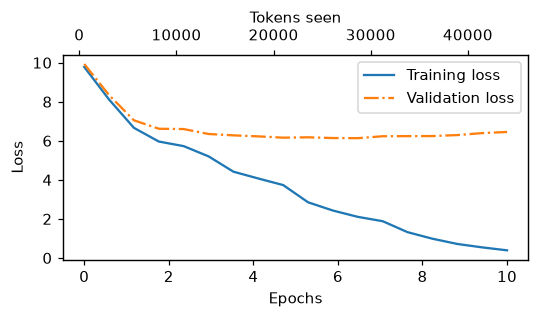

In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator


def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))

    # Plot training and validation loss against epochs
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))  # only show integer labels on x-axis

    # Create a second x-axis for tokens seen
    ax2 = ax1.twiny()  # Create a second x-axis that shares the same y-axis
    ax2.plot(tokens_seen, train_losses, alpha=0)  # Invisible plot for aligning ticks
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()  # Adjust layout to make room
    plt.savefig("loss-plot.pdf")
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)

Kurva di atas adalah padanan live dari Figure 5.12 buku, digambar dari kurva hasil training (bukan gambar). Sumbu bawah epoch, sumbu atas jumlah token input yang sudah diproses (44,032 token di evaluasi terakhir).

Buku membaca kurva ini sebagai overfitting yang dimulai setelah epoch 2. Angkanya lebih bernuansa: validation loss masih turun sampai step 55 (epoch 7), dari 6.6160 di step 15 (akhir evaluasi epoch 2) ke 6.1340. Yang terjadi setelah epoch 2 adalah *pelebaran gap*: dalam rentang yang sama train loss turun 3.86 poin (5.9610 -> 2.1043), sedangkan validation hanya turun 0.48 poin. Model terus belajar sedikit hal yang menggeneralisasi dan jauh lebih banyak hal yang hanya berlaku di teks train. Early stopping berbasis validation loss akan berhenti di step 55; catatannya, validation di sini hanya satu batch berisi 512 token, jadi titik minimum itu sendiri berisik.

Sel repo juga menyimpan plot ke `loss-plot.pdf` di folder kerja.

In [33]:
# Sel tambahan: model final (90 update) diukur langsung di seluruh split, mode eval
import math

model.eval()
torch.manual_seed(123)
with torch.no_grad():
    final_train = calc_loss_loader(train_loader, model, device)
    final_val = calc_loss_loader(val_loader, model, device)
print(f"model final, seluruh split : train {final_train:.4f} ({len(train_loader)} batch) | val {final_val:.4f} ({len(val_loader)} batch)")
print(f"log terakhir (step 85)     : train {train_losses[-1]:.4f} (5 batch)  | val {val_losses[-1]:.4f}")
print(f"rata-rata geometrik p(target): train {math.exp(-final_train):.3f} | val {math.exp(-final_val):.5f}")
print(f"perplexity                 : train {math.exp(final_train):.2f} | val {math.exp(final_val):.0f}")

model final, seluruh split : train 0.2976 (9 batch) | val 6.5264 (1 batch)
log terakhir (step 85)     : train 0.3909 (5 batch)  | val 6.4521
rata-rata geometrik p(target): train 0.743 | val 0.00146
perplexity                 : train 1.35 | val 683


Model final setelah 90 update: train loss 0.2976 di kesembilan batch train dan validation loss 6.5264. Empat update terakhir menurunkan train loss lagi dari 0.3909 (log step 85) dan menaikkan validation dari 6.4521. Rata-rata geometrik probabilitas target 0.743 di teks train berarti sebagian besar massa probabilitas jatuh di token train yang benar; 0.00146 di validation berarti token validation, secara rata-rata geometrik, hanya mendapat sekitar 1/683 massa probabilitas. Perplexity 1.35 vs 683.

Buku menyarankan memeriksa hafalan dengan mencari potongan teks hasil generate di file aslinya. Sel kecil berikut melakukannya untuk dua frasa dari sampel epoch 9 dan 10.

In [34]:
# Sel tambahan: apakah frasa hasil generate ada verbatim di The Verdict, dan di split mana?
for phrase in ["quite insensible to the irony", "was one of the axioms he laid down across the Sevres"]:
    pos = text_data.find(phrase)
    where = "train" if 0 <= pos < split_idx else ("validation" if pos >= split_idx else "-")
    print(f"{phrase!r}: muncul {text_data.count(phrase)}x, posisi karakter {pos} (split {where}, batas split {split_idx})")

'quite insensible to the irony': muncul 1x, posisi karakter 13246 (split train, batas split 18431)
'was one of the axioms he laid down across the Sevres': muncul 1x, posisi karakter 4235 (split train, batas split 18431)


Kedua frasa ada di teks asli, satu kali, di bagian train. Sampel epoch 10 adalah salinan kalimat novel, bukan kalimat baru. Dengan hanya 4,608 token train dan 10 epoch, setiap token dilihat 10 kali; model berkapasitas 162 juta parameter cukup besar untuk menyimpan seluruh teks itu, dan greedy decoding mengambil jalur paling probable -- yaitu jalur yang sudah dihafal. Buku mencatat bahwa pretraining sungguhan biasanya hanya satu epoch atas dataset yang jauh lebih besar, sehingga masalah ini tidak muncul dengan cara yang sama.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.13.png" width="700">

**Figure 5.13** Empat dari tujuh tujuan bab sudah tercapai. Model bisa menghasilkan teks koheren, tetapi sering menyalin teks train verbatim; berikutnya strategi decoding untuk teks yang lebih beragam.

## 5.3 Decoding strategies to control randomness

`generate_text_simple` selalu mengambil argmax, jadi untuk prompt yang sama ia selalu menghasilkan teks yang sama -- dan untuk model yang menghafal, teks itu adalah salinan data train. Bagian ini mengganti argmax dengan sampling yang bisa diatur lewat dua knob: temperature dan top-k.

Model dipindah ke CPU dan diset ke mode eval (dropout mati). Di notebook ini model memang sudah di CPU sejak training.

In [35]:
# NEW: use CPU here as inference is cheap with 
# this model and to ensure readers get same results in the
# remaining sections of this book
inference_device = torch.device("cpu")

model.to(inference_device)
model.eval()

tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


25 token greedy: *know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun* -- sama persis dengan buku. Ini cek yang lebih ketat daripada log tiga desimal: 25 argmax berturut-turut harus jatuh ke token yang sama, padahal satu logit yang bergeser cukup jauh bisa membalik satu argmax dan menyimpangkan seluruh sisa kalimat. Hasil ini konsisten dengan run buku pada level token; ia tetap bukan bukti bobot bit-identik dengan bobot penulis. (Notebook HEAD yang dilatih di MPS menghasilkan kalimat lain di sini.)

Koreksi prosa kecil: di 5.3.3 dan Exercise 5.3 buku menyebut fungsi `generate_simple`, padahal namanya `generate_text_simple` (tidak ada `def generate_simple` di repo).

### 5.3.1 Temperature scaling

Contoh mainan: vocabulary sembilan kata dan satu vektor logit untuk token berikutnya setelah *every effort moves you*. Greedy memilih logit terbesar.

In [36]:
vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 

inverse_vocab = {v: k for k, v in vocab.items()}

# Suppose input is "every effort moves you", and the LLM
# returns the following logits for the next token:
next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

probas = torch.softmax(next_token_logits, dim=0)
next_token_id = torch.argmax(probas).item()

# The next generated token is then as follows:
print(inverse_vocab[next_token_id])

forward


Logit terbesar 6.75 ada di indeks 3, jadi greedy memilih `forward`. Sampling menggantikan argmax dengan `torch.multinomial`, yang mengambil indeks dengan peluang sebanding probabilitasnya.

In [37]:
torch.manual_seed(123)
next_token_id = torch.multinomial(probas, num_samples=1).item()
print(inverse_vocab[next_token_id])

forward


Satu sampel dengan seed 123 juga jatuh di `forward`, token yang paling mungkin. Distribusinya baru terlihat bila sampling diulang.

In [38]:
def print_sampled_tokens(probas):
    torch.manual_seed(123) # Manual seed for reproducibility
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample), minlength=len(probas))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")

print_sampled_tokens(probas)

73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward
0 x you


1,000 sampel: 73 x closer, 0 x every, 0 x effort, 582 x forward, 2 x inches, 0 x moves, 0 x pizza, 343 x toward, 0 x you -- cocok dengan buku untuk delapan baris yang dicetak buku. Probabilitas softmax eksaknya adalah `forward` 0.5721, `toward` 0.3576, `closer` 0.0609; frekuensi empiris 0.582/0.343/0.073 berada dalam ~1.6 simpangan baku binomial dari nilai eksak.

**Errata #1 -- `bincount` tanpa `minlength` diam-diam membuang baris.** Sel repo di atas mencetak sembilan baris karena memakai `torch.bincount(..., minlength=len(probas))`. Versi buku (dan solusi Exercise 5.1 di repo) memanggil `bincount` tanpa `minlength`, sehingga panjang tensor hitungan berhenti di ID terbesar yang kebetulan tersampel. Indeks 8 (`you`) tidak pernah tersampel di T=1, jadi baris `0 x you` hilang -- itulah sebabnya output buku hanya punya delapan baris. Kode tidak error; ia hanya menyembunyikan token bernilai nol di ujung vocabulary. Exercise 5.1 di bawah menjalankan versi buku dan mengukur efeknya.

Temperature membagi logit dengan $T > 0$ sebelum softmax: $p_i \propto e^{z_i / T}$. $T < 1$ memperbesar jarak antar-logit sehingga distribusi lebih tajam; $T > 1$ mengecilkannya sehingga distribusi lebih rata; $T \to 0$ mendekati argmax.

In [39]:
def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)

# Temperature values
temperatures = [1, 0.1, 5]  # Original, higher confidence, and lower confidence

# Calculate scaled probabilities
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

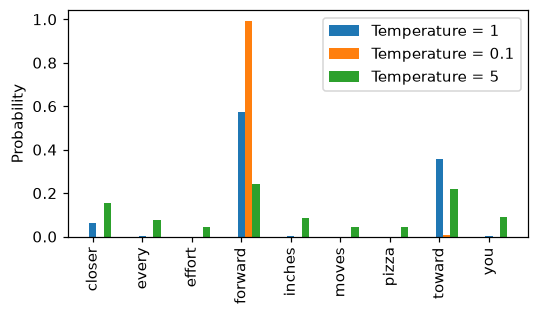

In [40]:
# Plotting
x = torch.arange(len(vocab))
bar_width = 0.15

fig, ax = plt.subplots(figsize=(5, 3))
for i, T in enumerate(temperatures):
    rects = ax.bar(x + i * bar_width, scaled_probas[i], bar_width, label=f'Temperature = {T}')

ax.set_ylabel('Probability')
ax.set_xticks(x)
ax.set_xticklabels(vocab.keys(), rotation=90)
ax.legend()

plt.tight_layout()
plt.savefig("temperature-plot.pdf")
plt.show()

Plot di atas adalah padanan live Figure 5.14 buku: tiga batang per kata untuk T = 1, 0.1, dan 5. Pada T = 0.1, `forward` mendapat 0.9910 dan sisanya hampir nol. Pada T = 5 distribusinya merata: kata paling mungkin turun ke 0.2421, dan `pizza` -- kata yang tidak masuk akal setelah *every effort moves you* -- naik ke 0.0430. Sel repo juga menyimpan `temperature-plot.pdf`. Dua sel repo berikut mengambil 1,000 sampel di kedua temperature ekstrem.

In [41]:
print_sampled_tokens(scaled_probas[1])

0 x closer
0 x every
0 x effort
985 x forward
0 x inches
0 x moves
0 x pizza
15 x toward
0 x you


T = 0.1: `forward` 985 kali, `toward` 15 kali, sisanya nol -- hampir greedy, tetapi tidak sepenuhnya deterministik, karena selisih logit `forward` dan `toward` (6.75 - 6.28 = 0.47) diperbesar menjadi 4.7 dan `toward` masih mendapat 0.0090. Cocok dengan output repo.

In [42]:
print_sampled_tokens(scaled_probas[2])

165 x closer
75 x every
42 x effort
239 x forward
71 x inches
46 x moves
32 x pizza
227 x toward
103 x you


T = 5: kesembilan kata muncul, termasuk `pizza` 32 kali dan `every` 75 kali -- kata yang sudah ada di prompt. Distribusinya mendekati rata (nilai tertinggi 0.2421), jadi teks yang dihasilkan pada temperature ini sebagian besar acak. Cocok dengan output repo.

#### Exercise 5.1

*Cetak frekuensi sampling untuk ketiga temperature di Figure 5.14. Berapa kali `pizza` tersampel? Adakah cara yang lebih cepat dan lebih akurat?*

Tiga sel solusi repo berikut dijalankan verbatim di namespace terpisah (fungsi `print_sampled_tokens` di sini adalah versi buku, tanpa `minlength`, dan tidak boleh menimpa versi bab).

In [43]:
import torch

vocab = { 
    "closer": 0,
    "every": 1, 
    "effort": 2, 
    "forward": 3,
    "inches": 4,
    "moves": 5, 
    "pizza": 6,
    "toward": 7,
    "you": 8,
} 
inverse_vocab = {v: k for k, v in vocab.items()}

next_token_logits = torch.tensor(
    [4.51, 0.89, -1.90, 6.75, 1.63, -1.62, -1.89, 6.28, 1.79]
)

def print_sampled_tokens(probas):
    torch.manual_seed(123)
    sample = [torch.multinomial(probas, num_samples=1).item() for i in range(1_000)]
    sampled_ids = torch.bincount(torch.tensor(sample))
    for i, freq in enumerate(sampled_ids):
        print(f"{freq} x {inverse_vocab[i]}")


def softmax_with_temperature(logits, temperature):
    scaled_logits = logits / temperature
    return torch.softmax(scaled_logits, dim=0)


temperatures = [1, 0.1, 5]  # Original, higher, and lower temperature
scaled_probas = [softmax_with_temperature(next_token_logits, T) for T in temperatures]

In [44]:
for i, probas in enumerate(scaled_probas):
    print("\n\nTemperature:", temperatures[i])
    print_sampled_tokens(probas)



Temperature: 1
73 x closer
0 x every
0 x effort
582 x forward
2 x inches
0 x moves
0 x pizza
343 x toward


Temperature: 0.1
0 x closer
0 x every
0 x effort
985 x forward
0 x inches
0 x moves
0 x pizza
15 x toward


Temperature: 5
165 x closer
75 x every
42 x effort
239 x forward
71 x inches
46 x moves
32 x pizza
227 x toward
103 x you


`pizza` tersampel 0 kali di T = 1, 0 kali di T = 0.1, dan 32 kali di T = 5. Jumlah baris yang tercetak per temperature: 8/8/9 -- inilah Errata #1 terukur. Di T = 1 dan T = 0.1 baris `you` hilang karena ID 8 tidak pernah tersampel; di T = 5 semua ID tersampel sehingga sembilan baris muncul. Pembaca yang menjumlahkan baris untuk memeriksa total 1,000 tetap mendapat 1,000, jadi bug ini lolos dari cek sederhana.

In [45]:
temp5_idx = 2
pizza_idx = 6

scaled_probas[temp5_idx][pizza_idx]

tensor(0.0430)

Jawaban bagian kedua exercise: tidak perlu sampling sama sekali. Frekuensi yang diharapkan adalah probabilitas softmax itu sendiri, `0.0430` untuk `pizza` di T = 5 (43 per 1,000). Monte Carlo 1,000 sampel memberi 32 -- meleset 11 hitungan. Sel berikut mengukur seberapa jauh meleset itu dibandingkan derau sampling, untuk ketiga temperature sekaligus.

In [46]:
# Sel tambahan: probabilitas eksak vs Monte Carlo 1,000 sampel, untuk "pizza" di tiga temperature
import math

for T, sp in zip(temperatures, scaled_probas):
    p = sp[vocab["pizza"]].item()
    torch.manual_seed(123)
    mc = sum(torch.multinomial(sp, num_samples=1).item() == vocab["pizza"] for _ in range(1_000))
    sd = math.sqrt(1_000 * p * (1 - p))
    z = (mc - 1_000 * p) / sd if sd > 0 else float("nan")
    print(f"T={T:<4} p(pizza) = {p:.3e}  harapan per 1000 = {1_000 * p:8.3f}  Monte Carlo = {mc:3d}  "
          f"sd = {sd:6.3f}  z = {z:+.2f}")

T=1    p(pizza) = 1.012e-04  harapan per 1000 =    0.101  Monte Carlo =   0  sd =  0.318  z = -0.32
T=0.1  p(pizza) = 2.972e-38  harapan per 1000 =    0.000  Monte Carlo =   0  sd =  0.000  z = -0.00
T=5    p(pizza) = 4.300e-02  harapan per 1000 =   42.998  Monte Carlo =  32  sd =  6.415  z = -1.71


Hasil: T=1: harapan 0.101, MC 0; T=0.1: harapan 0.000, MC 0; T=5: harapan 42.998, MC 32

Di T = 5, 32 vs 43.0 adalah selisih -1.71 simpangan baku -- masih dalam derau normal 1,000 sampel. Di T = 1 dan T = 0.1 probabilitas `pizza` begitu kecil (1.0e-04 dan 3.0e-38) sehingga Monte Carlo 1,000 sampel praktis tidak akan pernah melihatnya; untuk mengamati satu kejadian di T = 1 dibutuhkan rata-rata ~9,881 sampel. Probabilitas eksak lebih cepat (satu softmax) dan lebih akurat (tanpa derau), dan merupakan satu-satunya cara yang realistis untuk event langka.

### 5.3.2 Top-k sampling

Temperature tinggi menambah keragaman tetapi juga memberi peluang pada token yang tidak masuk akal. Top-k memotong ekor itu: hanya k logit terbesar yang dipertahankan, sisanya diganti $-\infty$ sehingga probabilitasnya tepat nol setelah softmax. Ini trik masking yang sama dengan causal attention di Chapter 3.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.15.png" width="700">

**Figure 5.15** Top-k dengan k = 3: tiga logit terbesar dipertahankan, sisanya di-mask dengan -inf, lalu softmax memberi probabilitas nol untuk semua token non-top-k.

In [47]:
top_k = 3
top_logits, top_pos = torch.topk(next_token_logits, top_k)

print("Top logits:", top_logits)
print("Top positions:", top_pos)

Top logits: tensor([6.7500, 6.2800, 4.5100])
Top positions: tensor([3, 7, 0])


Tiga logit terbesar 6.75, 6.28, 4.51 di posisi 3, 7, 0 (`forward`, `toward`, `closer`) -- cocok dengan buku. Ambangnya adalah logit terkecil di antara ketiganya, `top_logits[-1]` = 4.51.

In [48]:
new_logits = torch.where(
    condition=next_token_logits < top_logits[-1],
    input=torch.tensor(float("-inf")), 
    other=next_token_logits
)

print(new_logits)

tensor([4.5100,   -inf,   -inf, 6.7500,   -inf,   -inf,   -inf, 6.2800,   -inf])


Enam posisi di bawah ambang menjadi `-inf`, tiga lainnya tidak berubah.

In [49]:
topk_probas = torch.softmax(new_logits, dim=0)
print(topk_probas)

tensor([0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000])


`0.0615, 0.0000, 0.0000, 0.5775, 0.0000, 0.0000, 0.0000, 0.3610, 0.0000` -- cocok dengan buku sampai empat desimal. Massa probabilitas yang semula tersebar di enam token lain (0.0094 total di distribusi asli) dibagikan ulang secara proporsional ke tiga token yang tersisa: `forward` naik dari 0.5721 ke 0.5775.

### 5.3.3 Modifying the text generation function

Listing 5.4 menggabungkan keduanya: top-k diterapkan pada logit, lalu bila `temperature > 0` logit dibagi temperature dan disampling dengan `multinomial`; bila `temperature == 0` fungsi kembali ke argmax. Ada juga `eos_id` untuk berhenti lebih awal. Versi repo HEAD menambahkan satu baris yang ditandai "not in book": mengurangkan maksimum per baris sebelum softmax, untuk hasil yang setara di MPS. Di CPU baris itu tidak mengubah apa pun, karena softmax PyTorch sudah melakukan pengurangan yang sama secara internal (probe audit builder dengan logit sintetis: 40/40 lintasan top-k identik; sel berikut mengonfirmasinya pada model bab).

In [50]:
def generate(model, idx, max_new_tokens, context_size, temperature=0.0, top_k=None, eos_id=None):

    # For-loop is the same as before: Get logits, and only focus on last time step
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]

        # New: Filter logits with top_k sampling
        if top_k is not None:
            # Keep only top_k values
            top_logits, _ = torch.topk(logits, top_k)
            min_val = top_logits[:, -1]
            logits = torch.where(logits < min_val, torch.tensor(float("-inf")).to(logits.device), logits)

        # New: Apply temperature scaling
        if temperature > 0.0:
            logits = logits / temperature

            # New (not in book): numerical stability tip to get equivalent results on mps device
            # subtract rowwise max before softmax
            logits = logits - logits.max(dim=-1, keepdim=True).values
            
            # Apply softmax to get probabilities
            probs = torch.softmax(logits, dim=-1)  # (batch_size, context_len)

            # Sample from the distribution
            idx_next = torch.multinomial(probs, num_samples=1)  # (batch_size, 1)

        # Otherwise same as before: get idx of the vocab entry with the highest logits value
        else:
            idx_next = torch.argmax(logits, dim=-1, keepdim=True)  # (batch_size, 1)

        if idx_next == eos_id:  # Stop generating early if end-of-sequence token is encountered and eos_id is specified
            break

        # Same as before: append sampled index to the running sequence
        idx = torch.cat((idx, idx_next), dim=1)  # (batch_size, num_tokens+1)

    return idx

In [51]:
torch.manual_seed(123)

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(inference_device),
    max_new_tokens=15,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=25,
    temperature=1.4
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you stand to work on surprise, a one of us had gone with random-


Output: *Every effort moves you stand to work on surprise, a one of us had gone with random-* -- identik dengan buku, walau sel ini memakai `generate` versi HEAD (dengan baris stabilisasi tambahan). Ini konfirmasi kedua bahwa baris tambahan itu no-op di CPU: 15 langkah sampling dengan seed 123, top-25, T = 1.4 menghasilkan token yang persis sama.

Kalimatnya tidak lagi salinan novel. Buku memakainya sebagai bukti bahwa strategi decoding mengurangi hafalan. UTH 2 mengukur klaim itu secara kuantitatif.

**Errata #2 -- `generate` hanya bekerja untuk batch berukuran 1.** Komentar di Listing 5.4 menyebut bentuk `(batch_size, ...)`, tetapi dua baris tidak tahan batch > 1: `min_val = top_logits[:, -1]` berbentuk `(B,)` dan di-broadcast ke dimensi vocabulary, dan `if idx_next == eos_id` meminta nilai boolean dari tensor `(B, 1)`. Di bab ini `generate` hanya dipanggil dengan satu prompt, jadi bug ini tidak terlihat; di Chapter 6-7 batch generation menjadi relevan. Sel berikut mengukurnya dengan dua prompt.

In [52]:
# Sel tambahan: Errata #2 -- generate() Listing 5.4 dengan batch dua prompt
import traceback

batch = torch.cat([text_to_token_ids("Every effort moves you", tokenizer),
                   text_to_token_ids("I had always thought", tokenizer)[:, :4]], dim=0)
print("batch shape:", tuple(batch.shape))
for kwargs in [dict(temperature=0.0), dict(temperature=1.0, top_k=5), dict(temperature=0.0, eos_id=50256)]:
    try:
        out = generate(model=model, idx=batch, max_new_tokens=3, context_size=256, **kwargs)
        print(f"{kwargs}: ok, output shape {tuple(out.shape)}")
    except RuntimeError as e:
        print(f"{kwargs}: RuntimeError: {e}")
min_val_fixed = torch.topk(torch.randn(2, 50257), 5)[0][:, -1:]
print("perbaikan: top_logits[:, -1:] berbentuk", tuple(min_val_fixed.shape), "-> broadcast per baris")

batch shape: (2, 4)
{'temperature': 0.0}: ok, output shape (2, 7)
{'temperature': 1.0, 'top_k': 5}: RuntimeError: The size of tensor a (50257) must match the size of tensor b (2) at non-singleton dimension 1
{'temperature': 0.0, 'eos_id': 50256}: RuntimeError: Boolean value of Tensor with more than one value is ambiguous
perbaikan: top_logits[:, -1:] berbentuk (2, 1) -> broadcast per baris


Tanpa top-k dan tanpa `eos_id`, batch dua prompt berjalan. Dengan `top_k=5`, `torch.where` gagal karena `(2, 50257)` dibandingkan dengan `(2,)`; dengan `eos_id`, perbandingan `idx_next == eos_id` menghasilkan tensor dua elemen yang tidak bisa dijadikan `if`. Perbaikan minimal: `min_val = top_logits[:, -1:]` (bentuk `(B, 1)`), dan untuk EOS, cek `(idx_next == eos_id).all()` atau tandai baris yang sudah selesai. Repo sendiri mengakui batasan kedua: `gpt_generate.py` di HEAD menambahkan guard *"EOS stopping currently supports batch size 1 only"*, sementara bug top-k tetap ada di HEAD.

#### Under the hood 2 -- meteran hafalan

Klaim bab: temperature dan top-k mengurangi hafalan data train. Sel berikut mengukurnya. Split train ditokenisasi dan semua 8-gram token-nya disimpan dalam satu set. Untuk setiap strategi decoding, model meng-generate 50 token dari *Every effort moves you* dengan 8 seed (greedy cukup 1 seed karena deterministik). Lalu diukur fraksi 8-gram output yang muncul verbatim di teks train, run verbatim terpanjang, dan berapa dari 8 sampel yang berbeda satu sama lain. Pembanding alaminya adalah teks validation asli dari penulis yang sama: berapa persen 8-gram-nya kebetulan juga ada di split train.

In [53]:
# UTH 2 (sel tambahan): meteran hafalan -- 8-gram verbatim dari split train, per strategi decoding
N, NEW = 8, 50
train_ids = tokenizer.encode(train_data)
val_ids = tokenizer.encode(val_data)
train_grams = {tuple(train_ids[i:i + N]) for i in range(len(train_ids) - N + 1)}

def verbatim(ids):
    hits = [tuple(ids[i:i + N]) in train_grams for i in range(len(ids) - N + 1)]
    run = best = 0
    for h in hits:
        run = run + 1 if h else 0
        best = max(best, run)
    return sum(hits) / len(hits), (best + N - 1 if best else 0)

prompt_ids = text_to_token_ids("Every effort moves you", tokenizer)
configs = [("greedy (argmax)", 0.0, None), ("T=0.7, top-k=5", 0.7, 5), ("T=1.0, top-k=25", 1.0, 25),
           ("T=1.4, top-k=25 (buku)", 1.4, 25), ("T=1.0, tanpa top-k", 1.0, None), ("T=2.0, tanpa top-k", 2.0, None)]
model.eval()
uth2 = {}
print(f"{'strategi':<24}{'8-gram verbatim':>17}{'run terpanjang':>16}{'sampel unik':>13}")
for name, T, k in configs:
    rates, runs, outs = [], [], set()
    for seed in ([123] if T == 0.0 else range(8)):
        torch.manual_seed(seed)
        out = generate(model=model, idx=prompt_ids, max_new_tokens=NEW, context_size=256, temperature=T, top_k=k)
        cont = out[0, max(0, prompt_ids.shape[1] - (N - 1)):].tolist()   # tiap 8-gram memuat >= 1 token baru
        r, l = verbatim(cont)
        rates.append(r); runs.append(l); outs.add(tuple(cont))
    uth2[name] = dict(rate=sum(rates) / len(rates), run=max(runs), uniq=len(outs), n=len(rates))
    print(f"{name:<24}{uth2[name]['rate']:>16.1%}{uth2[name]['run']:>12} tok{len(outs):>9}/{len(rates)}")

windows = [val_ids[i:i + NEW + N - 1] for i in range(0, len(val_ids) - NEW - N + 1, NEW)]
val_ref = sum(verbatim(w)[0] for w in windows) / len(windows)
print(f"{'teks validation asli':<24}{val_ref:>16.1%}   ({len(windows)} jendela {NEW} token)")

strategi                  8-gram verbatim  run terpanjang  sampel unik
greedy (argmax)                    89.4%          49 tok        1/1
T=0.7, top-k=5                     66.8%          51 tok        7/8
T=1.0, top-k=25                    31.9%          33 tok        8/8
T=1.4, top-k=25 (buku)             10.6%          17 tok        8/8
T=1.0, tanpa top-k                  4.0%          17 tok        8/8
T=2.0, tanpa top-k                  0.0%           0 tok        8/8
teks validation asli                0.0%   (10 jendela 50 token)


Pembacaan:

- **Greedy**: 89% 8-gram output ada verbatim di teks train, dengan run terpanjang 49 token. Kalimat greedy adalah penelusuran ulang jalur yang dihafal.
- **T = 1.4, top-k = 25 (setelan buku)**: rata-rata 11% dari 8 seed, run terpanjang 17 token, 8/8 sampel unik. Hafalan berkurang tetapi tidak hilang. Model tetap menyalin potongan panjang; sampling hanya membuatnya melompat antarpotongan lebih sering.
- **T = 0.7, top-k = 5**: 67%, masih dua pertiga salinan; **T = 1.0, top-k = 25**: 32%.
- **T = 1.0 tanpa top-k**: 4% -- lebih rendah daripada setelan buku walau temperature-nya lebih kecil. Melepas top-k membuka ekor 50 ribu token, dan satu token ekor cukup untuk memutus run 8-gram verbatim.
- **T = 2.0 tanpa top-k**: 0% -- tidak ada span 8 token verbatim di kedelapan sampel ini, dengan harga teks yang tidak koheren.
- **Pembanding**: dari 8-gram teks validation asli (cerita dan penulis yang sama, 10 jendela 50 token), 0.0% muncul di split train: di jendela-jendela ini tidak ada satu pun span 8 token teks asli yang juga ada di split train. Ini baseline untuk cerita ini dan metrik ini saja, bukan klaim umum tentang prosa.

Kesimpulan terukur: strategi decoding menggeser tingkat salinan secara kontinu, tetapi pada setelan buku model masih menyalin jauh di atas baseline 0.0%. Hafalan adalah sifat bobot (model final: validation loss 6.53 vs train 0.30), bukan sifat decoder. Decoder hanya memilih seberapa sering jalur yang dihafal diikuti. Obat sebenarnya ada di data dan training: lebih banyak data, satu epoch, atau berhenti di titik terendah validation loss (step 55).

#### Exercise 5.2

*Coba berbagai temperature dan top-k. Aplikasi apa yang butuh setelan rendah, dan aplikasi apa yang butuh setelan tinggi?*

Tabel UTH 2 adalah eksperimen exercise ini dalam bentuk terukur. Setelan **rendah** (T kecil, k kecil, atau greedy) cocok bila satu jawaban benar lebih penting daripada variasi dan output harus reproducible: ekstraksi informasi, klasifikasi berbasis generate (Chapter 6), kode, terjemahan, jawaban faktual yang diaudit. Konsekuensinya, model mengulang jalur paling probable termasuk kebiasaan buruknya: pengulangan, dan pada model yang overfit, salinan data. Setelan **tinggi** cocok bila keragaman adalah tujuan: brainstorming, fiksi, variasi copywriting, membuat banyak kandidat untuk dipilih manusia atau model lain. Konsekuensinya, koherensi turun dan token yang tidak masuk akal (`pizza`) mulai muncul. Top-k adalah pagar untuk temperature tinggi: ia mengizinkan keragaman di antara kandidat yang masuk akal sambil memotong ekor yang tidak masuk akal. Buku menyarankan exercise ini diulang setelah bobot OpenAI dimuat; sel "Exercise 5.2, ulang" di akhir 5.5 melakukannya.

## 5.4 Loading and saving model weights in PyTorch

Training sekecil apa pun mahal untuk diulang, jadi bobot disimpan. Cara yang dianjurkan PyTorch adalah menyimpan `state_dict` -- dictionary nama parameter ke tensor -- dengan `torch.save`. Ekstensi `.pth` hanya konvensi.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.16.png" width="700">

**Figure 5.16** Langkah 6 dari tujuh: setelah training dan inspeksi, bobot disimpan supaya bisa dipakai atau dilatih lanjut.

In [54]:
torch.save(model.state_dict(), "model.pth")

#### Exercise 5.3

*Kombinasi setelan `generate` apa saja yang membuatnya deterministik, seperti `generate_text_simple`?*

Solusi repo memuat `model.pth` yang baru disimpan ke model baru, lalu membandingkan `generate_text_simple` dengan `generate(temperature=0.0, top_k=None)`. Dijalankan verbatim di namespace terpisah (sesi baru dalam semangat exercise). Sel kedua mengimpor `generate` dari `gpt_generate.py`, yang di baris atasnya mengimpor `tensorflow` meski `generate` sama sekali tidak memakainya; di runtime tanpa TensorFlow, import itu tetap berhasil berkat pembaca NumPy dari sel setup.

In [55]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,  # Vocabulary size
    "context_length": 256,       # Shortened context length (orig: 1024)
    "emb_dim": 768,       # Embedding dimension
    "n_heads": 12,        # Number of attention heads
    "n_layers": 12,       # Number of layers
    "drop_rate": 0.1,     # Dropout rate
    "qkv_bias": False     # Query-key-value bias
}


torch.manual_seed(123)

tokenizer = tiktoken.get_encoding("gpt2")
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(torch.load("model.pth", weights_only=True))
model.eval();

In [56]:
from gpt_generate import generate, text_to_token_ids, token_ids_to_text
from previous_chapters import generate_text_simple

In [57]:
# Deterministic function that used torch.argmax

start_context = "Every effort moves you"

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"]
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


`generate_text_simple` (argmax) pada model yang dimuat dari `model.pth`: *know," was one of the axioms he laid down across the Sevres...*

In [58]:
# Deterministic behavior: No top_k, no temperature scaling

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=None,
    temperature=0.0
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


`generate` dengan `temperature=0.0` dan `top_k=None` memberi kalimat yang sama. Sel solusi berikutnya mengulang panggilan yang sama untuk menunjukkan bahwa hasilnya tidak berubah antar-panggilan.

In [59]:
# Deterministic behavior: No top_k, no temperature scaling

token_ids = generate(
    model=model,
    idx=text_to_token_ids("Every effort moves you", tokenizer),
    max_new_tokens=25,
    context_size=GPT_CONFIG_124M["context_length"],
    top_k=None,
    temperature=0.0
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you know," was one of the axioms he laid down across the Sevres and silver of an exquisitely appointed lun


Ketiga output identik satu sama lain dan identik dengan output greedy di 5.3 (*know," was one of the axioms he laid down across the Sevres...*). Itu juga membuktikan `model.pth` menyimpan bobot secara lengkap: model baru yang dimuat dari file menghasilkan token yang sama dengan model asal. `temperature=0.0` membuat `generate` mengambil cabang argmax, sehingga `top_k` apa pun tidak mengubah hasil.

Jawaban exercise belum lengkap tanpa satu kombinasi lagi: `top_k=1` dengan temperature berapa pun. Setelah masking hanya satu logit yang tersisa, softmax memberinya probabilitas tepat 1, dan `multinomial` tidak punya pilihan. Sel berikut mengukur jumlah output berbeda dari 5 seed untuk empat setelan.

In [60]:
# Sel tambahan: setelan mana yang deterministik? jumlah output berbeda dari 5 seed
idx = text_to_token_ids("Every effort moves you", tokenizer)
for name, kw in [("temperature=0.0", dict(temperature=0.0)),
                 ("top_k=1, temperature=1.4", dict(top_k=1, temperature=1.4)),
                 ("temperature=0.1, top_k=None", dict(temperature=0.1)),
                 ("temperature=1.4, top_k=25", dict(top_k=25, temperature=1.4))]:
    outs = set()
    for seed in range(5):
        torch.manual_seed(seed)
        outs.add(tuple(generate(model=model, idx=idx, max_new_tokens=25,
                                context_size=GPT_CONFIG_124M["context_length"], **kw)[0].tolist()))
    print(f"{name:<30} output berbeda: {len(outs)}/5")

temperature=0.0                output berbeda: 1/5
top_k=1, temperature=1.4       output berbeda: 1/5
temperature=0.1, top_k=None    output berbeda: 1/5
temperature=1.4, top_k=25      output berbeda: 5/5


temperature=0.0 output berbeda: 1/5; top_k=1, temperature=1.4 output berbeda: 1/5; temperature=0.1, top_k=None output berbeda: 1/5; temperature=1.4, top_k=25 output berbeda: 5/5

`top_k=1` deterministik secara konstruksi. `temperature=0.1` tanpa top-k *hampir* deterministik untuk model yang sangat yakin seperti ini, tetapi bukan secara konstruksi: probabilitas token kedua tidak pernah tepat nol, jadi pada model yang kurang yakin atau teks yang lebih panjang hasilnya bisa bercabang. Satu catatan lagi: kedua setelan deterministik itu tetap memanggil `torch.multinomial` atau `argmax` di atas logit float32, jadi determinisme lintas *hardware* tetap bergantung pada logit yang cukup dekat untuk tidak membalik satu argmax pun; 5.2 dan 5.3 menunjukkan itu terpenuhi pada presisi tercetak untuk CPU di sini.

Memuat kembali bobot ke instance `GPTModel` baru. Sel berikut versi era-buku (device `cuda` atau `cpu`); sel HEAD memilih `mps` di Apple Silicon dan, untuk torch < 2.9, punya cabang tanpa `else` yang membiarkan `device` tak terdefinisi di sesi baru (temuan audit, tidak memengaruhi torch 2.14.1 di sini). `model.eval()` mematikan dropout untuk inferensi.

In [61]:
model = GPTModel(GPT_CONFIG_124M)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.load_state_dict(torch.load("model.pth", map_location=device, weights_only=True))
model.eval();

Untuk melanjutkan training nanti, state optimizer juga harus disimpan. AdamW menyimpan dua tensor per parameter: rata-rata bergerak gradien (`exp_avg`) dan kuadratnya (`exp_avg_sq`), plus penghitung step. Tanpa keduanya, optimizer mulai dari nol dan langkah-langkah awalnya berperilaku berbeda (diukur di Exercise 5.4).

In [62]:
torch.save({
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    }, 
    "model_and_optimizer.pth"
)

In [63]:
# Sel tambahan: berapa mahal menyimpan state optimizer?
import os

for f in ["model.pth", "model_and_optimizer.pth"]:
    print(f"{f:<24} {os.path.getsize(f) / 1e6:8.1f} MB")
n_params = sum(p.numel() for p in model.parameters())
print(f"parameter model          {n_params:,} x 4 byte = {n_params * 4 / 1e6:.1f} MB")
st = optimizer.state_dict()["state"][0]
print("state AdamW per parameter:", sorted(st.keys()), "| step =", int(st["step"]))

model.pth                   652.9 MB
model_and_optimizer.pth    1952.4 MB
parameter model          162,419,712 x 4 byte = 649.7 MB
state AdamW per parameter: ['exp_avg', 'exp_avg_sq', 'step'] | step = 90


`model.pth` 652.9 MB terdiri atas tiga bagian: 162,419,712 parameter float32 = 649,678,848 byte (649.7 MB); 12 buffer mask kausal, satu per transformer block, masing-masing `256 x 256` float32 (`register_buffer` di `MultiHeadAttention`, jadi ikut `state_dict`) = 3,145,728 byte (3.15 MB); sisanya overhead serialisasi. Total tensor 652,824,576 byte; ukuran file yang diukur builder 652,874,815 byte, jadi overhead-nya 50,239 byte. `model_and_optimizer.pth` 1952.4 MB, sekitar tiga kali lipat: tensor model di atas, `exp_avg` dan `exp_avg_sq` masing-masing seukuran parameter (bersama 1,299,357,696 byte), dan 161 penghitung `step` 4 byte. State optimizer mencatat `step = 90`, yaitu 10 epoch x 9 batch. Untuk GPT-2 XL, checkpoint lengkap seperti ini berukuran ~20 GB (1,638 juta parameter x 4 byte x 3).

In [64]:
checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)

model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0005, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

In [65]:
# Sel tambahan: apa yang sebenarnya dipulihkan load_state_dict?
print("lr di konstruktor sel di atas: 0.0005 | lr setelah load_state_dict:", optimizer.param_groups[0]["lr"])
print("step AdamW yang dipulihkan  :", int(optimizer.state_dict()["state"][0]["step"]))
print("mode model                  :", "train" if model.training else "eval")

lr di konstruktor sel di atas: 0.0005 | lr setelah load_state_dict: 0.0004
step AdamW yang dipulihkan  : 90
mode model                  : train


Detail yang mudah terlewat: sel repo membuat AdamW dengan `lr=0.0005`, tetapi `load_state_dict` menimpa `param_groups` dengan isi checkpoint, sehingga lr kembali ke 0.0004 -- nilai saat training. Hyperparameter di konstruktor hanya berlaku bila checkpoint tidak memuatnya; untuk mengganti lr setelah resume, ubah `optimizer.param_groups[i]["lr"]` setelah `load_state_dict`. `model.train()` di akhir sel mengaktifkan dropout lagi untuk training lanjutan.

#### Exercise 5.4

*Muat model dan optimizer di sesi Python baru, lalu lanjutkan pretraining satu epoch dengan `train_model_simple`.*

Tiga sel solusi repo dijalankan verbatim di namespace terpisah: memuat `model_and_optimizer.pth` yang baru disimpan, membangun ulang data loader, dan mengimpor `train_model_simple` dari `gpt_train.py`. Ini training tambahan kecil (9 step), jadi builder menunggu giliran komputasi dulu bila training penuh bab lain sedang jalan.

In [66]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = tiktoken.get_encoding("gpt2")

checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)
model = GPTModel(GPT_CONFIG_124M)
model.load_state_dict(checkpoint["model_state_dict"])
model.to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=0.0004, weight_decay=0.1)
optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
model.train();

In [67]:
import os
import requests
from previous_chapters import create_dataloader_v1


file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    text_data = response.text
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()

# The book originally used the following code below
# However, urllib uses older protocol settings that
# can cause problems for some readers using a VPN.
# The `requests` version above is more robust
# in that regard.

"""
import urllib.request

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()
"""


# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [68]:
from gpt_train import train_model_simple

num_epochs = 1
train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 0.271, Val loss 6.545
Ep 1 (Step 000005): Train loss 0.244, Val loss 6.614
Every effort moves you?"  "Yes--quite insensible to the irony. She wanted him vindicated--and by me!"  He laughed again, and threw back his head to look up at the sketch of the donkey. "There were days when I


Satu epoch tambahan: Ep 1 (Step 000000): Train loss 0.271, Val loss 6.545 | Ep 1 (Step 000005): Train loss 0.244, Val loss 6.614. Output solusi repo: Ep 1 (Step 000000): Train loss 0.271, Val loss 6.545 | Ep 1 (Step 000005): Train loss 0.244, Val loss 6.614 -- identik. Dibanding model final yang diukur di 5.2 (train 0.2976 di seluruh split, validation 6.5264), validation naik ke 6.614 di step 5 sementara train loss tetap rendah: epoch ke-11 memperdalam overfitting. Sampelnya sudah sepenuhnya salinan teks train.

Buku memperingatkan bahwa tanpa state optimizer model bisa "belajar suboptimal atau bahkan gagal konvergen". Klaim itu bisa diukur: arm kedua di bawah memuat bobot yang sama, tetapi membuat AdamW baru tanpa state, dengan seed, data, dan urutan batch yang sama.

In [69]:
# Sel tambahan: Exercise 5.4 arm B -- bobot yang sama, AdamW baru tanpa state (seed dan data identik)
import torch
from previous_chapters import GPTModel
from gpt_train import train_model_simple

checkpoint = torch.load("model_and_optimizer.pth", weights_only=True)
model_b = GPTModel(GPT_CONFIG_124M)
model_b.load_state_dict(checkpoint["model_state_dict"])
model_b.to(device)
optimizer_b = torch.optim.AdamW(model_b.parameters(), lr=0.0004, weight_decay=0.1)   # tanpa load_state_dict
model_b.train()

torch.manual_seed(123)   # sama dengan sel data loader solusi: RNG belum dipakai sebelum iterasi pertama
train_losses_b, val_losses_b, _ = train_model_simple(
    model_b, train_loader, val_loader, optimizer_b, device,
    num_epochs=1, eval_freq=5, eval_iter=5,
    start_context="Every effort moves you", tokenizer=tokenizer
)

Ep 1 (Step 000000): Train loss 0.751, Val loss 6.742
Ep 1 (Step 000005): Train loss 0.562, Val loss 6.622
Every effort moves you?" "Oh, and Mrs. . . . "I turned: "Yes--and by me!" "Mrs. Gisburn drew back his glory, he had dropped his painting, married a rich widow, and established himself in


Arm B (AdamW tanpa state): Ep 1 (Step 000000): Train loss 0.751, Val loss 6.742 | Ep 1 (Step 000005): Train loss 0.562, Val loss 6.622, dibandingkan arm A (state dipulihkan): Ep 1 (Step 000000): Train loss 0.271, Val loss 6.545 | Ep 1 (Step 000005): Train loss 0.244, Val loss 6.614.

Setelah update pertama (step 0), train loss arm B 0.751 vs arm A 0.271 (lebih tinggi); validation 6.742 vs 6.545. Di step 5: train 0.562 vs 0.244 (lebih tinggi), validation 6.622 vs 6.614.

Mekanismenya: pada step pertama AdamW yang baru, bias correction membuat $\hat m / (\sqrt{\hat v} + \epsilon) = g / (|g| + \epsilon) \approx \pm 1$ untuk setiap parameter, sehingga setiap bobot dengan gradien jauh di atas `eps` (1e-8) bergeser sebesar lr (0.0004) ke arah tanda gradiennya, sekecil apa pun gradien itu. Bobot dengan gradien tepat nol (misalnya baris embedding token yang tidak muncul di batch) hanya terkena weight decay. Optimizer yang dipulihkan membagi dengan $\sqrt{v}$ hasil 90 step, sehingga ukuran langkahnya sudah terkalibrasi per parameter. Kesimpulannya: menyimpan state optimizer bukan formalitas, terutama bila training dilanjutkan dengan lr yang tidak kecil.

## 5.5 Loading pretrained weights from OpenAI

Bobot GPT-2 yang dirilis OpenAI menghapus kebutuhan pretraining ratusan ribu dolar. Bobot itu disimpan sebagai checkpoint TensorFlow 1.x. Buku memakai TensorFlow untuk membacanya dan `tqdm` untuk progress bar unduhan. Sel repo berikut hanya komentar instruksi instalasi, lalu sel versi.

In [70]:
# pip install tensorflow tqdm

In [71]:
# Sel repo [130] verbatim, dibungkus try/except supaya Run all tidak berhenti bila TensorFlow tidak terpasang
import traceback

try:
    print("TensorFlow version:", version("tensorflow"))
    print("tqdm version:", version("tqdm"))
except Exception:
    traceback.print_exc()

TensorFlow version: 2.22.0rc0
tqdm version: 4.70.1


Output: TensorFlow version: 2.22.0rc0, tqdm version: 4.70.1. Release candidate yang sama dengan sel setup; di runtime tanpa TensorFlow sel ini mencetak `PackageNotFoundError` dan baris `tqdm` tidak sempat jalan. Pembaca NumPy sengaja tidak memalsukan metadata distribusi, jadi `importlib.metadata` tetap jujur tentang apa yang terpasang.

**Errata #3 -- perintah `pip` di buku rusak di shell.** Buku mencetak `pip install tensorflow>=2.15.0 tqdm>=4.66` tanpa tanda kutip. Di bash, `>` adalah redirect: pip menerima `install tensorflow tqdm` tanpa batas versi, dan outputnya ditulis ke file bernama `=2.15.0` dan `=4.66`. Di zsh (shell default macOS), `=2.15.0` diperlakukan sebagai *equals expansion* dan perintah gagal sebelum pip dipanggil. Sel berikut mengukurnya dengan `echo` di folder sementara (tidak ada yang dipasang).

In [72]:
# Sel tambahan: Errata #3 -- requirement tanpa kutip di bash dan zsh (pakai echo, tanpa instalasi)
import shutil, subprocess, tempfile

cmd = "echo pip install tensorflow>=2.15.0 tqdm>=4.66"
for shell in ["bash", "zsh"]:
    if shutil.which(shell) is None:
        print(f"{shell}: tidak tersedia di mesin ini")
        continue
    with tempfile.TemporaryDirectory() as d:
        r = subprocess.run([shell, "-c", cmd], cwd=d, capture_output=True, text=True)
        files = {f: open(os.path.join(d, f)).read().strip() for f in sorted(os.listdir(d))}
        print(f"{shell}: exit {r.returncode}, stdout={r.stdout.strip()!r}, stderr={r.stderr.strip()!r}, file dibuat={files}")
print("perbaikan:", 'pip install "tensorflow>=2.15.0" "tqdm>=4.66"')

bash: exit 0, stdout='', stderr='', file dibuat={'=2.15.0': '', '=4.66': 'pip install tensorflow tqdm'}
zsh: exit 1, stdout='', stderr='zsh:1: 2.15.0 not found', file dibuat={}
perbaikan: pip install "tensorflow>=2.15.0" "tqdm>=4.66"


Bash: perintah sukses (exit 0) tanpa mencetak apa pun ke layar, dan dua file muncul -- `=2.15.0` kosong dan `=4.66` berisi `pip install tensorflow tqdm`. Pembaca tidak melihat error apa pun, tetapi batas versinya hilang. zsh: `'zsh:1: 2.15.0 not found'` dengan exit 1 dan tidak ada file yang dibuat. Perbaikannya cukup tanda kutip, seperti baris terakhir output. Repo menghindari masalah ini dengan menulis `pip install tensorflow tqdm` tanpa versi.

Berikutnya modul unduhan. Buku mengambil `gpt_download.py` langsung dari branch `main` repo dengan `urllib`; sel buku itu tidak ada di notebook repo (repo memakai file lokal). Sel berikut menjalankan listing buku apa adanya, lalu membandingkan file `main` hari ini dengan salinan yang dipin di setup.

In [73]:
# Listing buku 5.5 (tidak ada di notebook repo): unduh gpt_download.py dari branch main
import urllib.request
url = (
    "https://raw.githubusercontent.com/rasbt/"
    "LLMs-from-scratch/main/ch05/"
    "01_main-chapter-code/gpt_download.py"
)
filename = url.split('/')[-1]
urllib.request.urlretrieve(url, filename)

# Sel tambahan (lanjutan): bandingkan dengan versi commit yang dipin
digest = hashlib.sha256(open(filename, "rb").read()).hexdigest()
print("sha256 gpt_download.py dari main:", digest[:16], "| sama dengan commit dipin:", digest == SHA256["gpt_download.py"])

sha256 gpt_download.py dari main: 3e2e95f7c3bf188e | sama dengan commit dipin: True


File dari `main` saat build identik dengan salinan commit `cdbd33e`. Versi ini sudah berbeda dari versi era buku: unduhan memakai `requests` dengan timeout dan `raise_for_status`, plus URL cadangan di Backblaze bila server OpenAI gagal. Karena listing buku menunjuk ke `main`, pembaca di masa depan bisa menerima versi yang lain lagi; hash di atas adalah cara mendeteksinya.

In [74]:
# Relative import from the gpt_download.py contained in this folder

from gpt_download import download_and_load_gpt2
# Alternatively:
# from llms_from_scratch.ch05 import download_and_load_gpt2

In [75]:
settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


Tujuh file checkpoint 124M dilaporkan *already exists and is up-to-date*: `download_file` meminta header ke server, membandingkan `Content-Length` dengan ukuran lokal, lalu melewati unduhan. File-file itu diunduh builder sebelumnya: server utama OpenAI hanya memberi ~0.16 MB/s saat build, jadi unduhan file data dilanjutkan (resume byte) dari mirror Backblaze yang juga dipakai `gpt_download.py` sebagai cadangan, dan MD5 setiap file utuh dicocokkan dengan header `Content-MD5` server OpenAI. Di runtime segar sel ini menampilkan tujuh progress bar `tqdm` seperti di buku. Catatan kecil: progress bar di buku mencetak `hprams.json`, padahal nama file dan label bar-nya `hparams.json`.

Di balik layar, `load_gpt2_params_from_tf_ckpt` memanggil `tf.train.list_variables` dan `tf.train.load_variable` untuk 148 variabel, lalu menyusunnya ke dictionary bertingkat. Di build ini semua panggilan itu dilayani TensorFlow asli; di runtime tanpa TensorFlow, oleh pembaca NumPy.

In [76]:
print("Settings:", settings)

Settings: {'n_vocab': 50257, 'n_ctx': 1024, 'n_embd': 768, 'n_head': 12, 'n_layer': 12}


`settings` adalah `hparams.json` OpenAI: vocabulary 50,257, konteks 1,024, embedding 768, 12 head, 12 layer -- cocok dengan buku, dan sama dengan `GPT_CONFIG_124M` kecuali konteks (bab ini memakai 256).

In [77]:
print("Parameter dictionary keys:", params.keys())

Parameter dictionary keys: dict_keys(['blocks', 'b', 'g', 'wpe', 'wte'])


`params` punya lima kunci teratas: `blocks` (list 12 transformer block), `wte` (token embedding), `wpe` (positional embedding), serta `g` dan `b` (scale dan shift LayerNorm akhir; penamaan OpenAI untuk *gain* dan *bias*).

In [78]:
print(params["wte"])
print("Token embedding weight tensor dimensions:", params["wte"].shape)

[[-0.11010301 -0.03926672  0.03310751 ... -0.1363697   0.01506208
   0.04531523]
 [ 0.04034033 -0.04861503  0.04624869 ...  0.08605453  0.00253983
   0.04318958]
 [-0.12746179  0.04793796  0.18410145 ...  0.08991534 -0.12972379
  -0.08785918]
 ...
 [-0.04453601 -0.05483596  0.01225674 ...  0.10435229  0.09783269
  -0.06952604]
 [ 0.1860082   0.01665728  0.04611587 ... -0.09625227  0.07847701
  -0.02245961]
 [ 0.05135201 -0.02768905  0.0499369  ...  0.00704835  0.15519823
   0.12067825]]
Token embedding weight tensor dimensions: (50257, 768)


Matriks token embedding `(50257, 768)`. Enam baris yang tercetak (tiga awal, tiga akhir) identik dengan buku sampai digit terakhir yang ditampilkan, misalnya `-0.11010301` di pojok kiri atas dan `0.12067825` di pojok kanan bawah. Kesamaan delapan digit di dua belas angka ini bukan bukti lengkap -- UTH 3 di bawah memberi bukti lengkapnya.

<img src="https://raw.githubusercontent.com/farrelrassya/Build-a-Large-Language-Model-From-Scratch/main/Folder-photos/05.Chapter05/figure5.17.png" width="700">

**Figure 5.17** Empat ukuran GPT-2 berbagi arsitektur yang sama; yang berbeda hanya dimensi embedding (768-1,600), jumlah head (12-25), dan jumlah pengulangan transformer block (12-48), dari 124M sampai 1,558M parameter.

Bobot OpenAI dimuat ke `GPTModel` buatan sendiri dengan tiga penyesuaian konfigurasi: dimensi model sesuai ukuran yang dipilih, `context_length` kembali ke 1,024 (tabel positional embedding OpenAI berukuran `1024 x 768`), dan `qkv_bias=True` karena GPT-2 asli memakai bias di proyeksi query/key/value. Buku mencatat bahwa bias QKV sudah jarang dipakai LLM modern, tetapi bobot pretrained memaksa arsitekturnya cocok.

In [79]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [80]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(torch.tensor(right))

`assign` di atas adalah versi repo: satu f-string utuh. **Errata #4 -- pesan error `assign` versi buku menyembunyikan bentuk tensor kanan.** Buku memecah pesan menjadi dua literal string yang disambung, dan hanya literal pertama yang diberi prefix `f`. Kode tetap berjalan; kesalahannya baru terlihat persis saat pesan itu dibutuhkan, yaitu ketika bentuk tidak cocok. Sel berikut menjalankan versi cetak buku dengan bentuk yang sengaja salah.

In [81]:
# Sel tambahan: Errata #4 -- assign() versi cetak buku vs versi repo, dengan bentuk yang sengaja tidak cocok
def assign_book(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, "
                         "Right: {right.shape}"
                         )
    return torch.nn.Parameter(torch.tensor(right))

wrong = params["blocks"][0]["attn"]["c_attn"]["w"]      # (768, 2304), belum di-split
for fn in (assign_book, assign):
    try:
        fn(gpt.trf_blocks[0].att.W_query.weight, wrong)
    except ValueError as e:
        print(f"{fn.__name__:<12} ValueError: {e}")

assign_book  ValueError: Shape mismatch. Left: torch.Size([768, 768]), Right: {right.shape}
assign       ValueError: Shape mismatch. Left: torch.Size([768, 768]), Right: (768, 2304)


Versi buku mencetak `Right: {right.shape}` secara harfiah; versi repo mencetak `Right: (768, 2304)`. Bentuk kiri sama di keduanya (`torch.Size([768, 768])`). Dalam fungsi pemetaan bobot sepanjang Listing 5.5, bentuk kanan adalah informasi yang paling berguna saat debugging, karena ia menunjukkan tensor OpenAI mana yang belum di-split atau belum di-transpose.

In [82]:
import numpy as np

def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params['wpe'])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params['wte'])
    
    for b in range(len(params["blocks"])):
        q_w, k_w, v_w = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["w"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = np.split(
            (params["blocks"][b]["attn"]["c_attn"])["b"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight, 
            params["blocks"][b]["attn"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias, 
            params["blocks"][b]["attn"]["c_proj"]["b"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight, 
            params["blocks"][b]["mlp"]["c_fc"]["w"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias, 
            params["blocks"][b]["mlp"]["c_fc"]["b"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight, 
            params["blocks"][b]["mlp"]["c_proj"]["w"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias, 
            params["blocks"][b]["mlp"]["c_proj"]["b"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale, 
            params["blocks"][b]["ln_1"]["g"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift, 
            params["blocks"][b]["ln_1"]["b"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale, 
            params["blocks"][b]["ln_2"]["g"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift, 
            params["blocks"][b]["ln_2"]["b"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["g"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["b"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte"])
    
    
load_weights_into_gpt(gpt, params)
gpt.to(device);

`load_weights_into_gpt` memetakan penamaan OpenAI ke modul buatan sendiri. Tiga pola yang perlu diperhatikan:

- `c_attn` OpenAI adalah satu matriks `768 x 2304` yang menggabungkan Q, K, V; `np.split(..., 3, axis=-1)` memecahnya menjadi tiga `768 x 768`.
- Semua bobot linear di-transpose (`.T`). OpenAI menyimpan bobot sebagai `[in, out]` (layer `Conv1D` di implementasi aslinya), sedangkan `nn.Linear` menyimpan `[out, in]`.
- `out_head.weight` diisi dengan `params["wte"]`, matriks yang sama dengan token embedding -- *weight tying* versi GPT-2 asli. UTH 4 memeriksa apakah pengikatannya benar-benar terjadi.

Kalau satu pemetaan salah, `assign` menolak bentuk yang tidak cocok; kalau bentuknya kebetulan cocok tetapi tensornya tertukar, satu-satunya gejala adalah teks yang tidak koheren. Sel berikut adalah tes akhirnya.

In [83]:
torch.manual_seed(123)

token_ids = generate(
    model=gpt,
    idx=text_to_token_ids("Every effort moves you", tokenizer).to(device),
    max_new_tokens=25,
    context_size=NEW_CONFIG["context_length"],
    top_k=50,
    temperature=1.5
)

print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Output text:
 Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?




*Every effort moves you toward finding an ideal new way to practice something! What makes us want to be on top of that?* -- identik dengan buku, token per token, termasuk baris barunya. Dengan top-k 50 dan temperature 1.5, setiap langkah sampling bergantung pada urutan dan nilai persis 50 logit teratas. Kecocokan 25 token berturut-turut berarti seluruh rantai -- checkpoint dibaca TensorFlow, `np.split`, transpose, `GPTModel` buatan sendiri, dan `generate` -- menghasilkan logit yang cukup dekat dengan run penulis untuk tidak mengubah satu pun pilihan sampling. Itu bukti kuat bahwa pemetaan bobotnya benar, walau tidak berarti logitnya bit-identik. Rantai yang sama juga sudah diuji dengan pembaca NumPy menggantikan TensorFlow (probe builder): kalimat yang sama, token per token.

#### Under the hood 3 -- checkpoint TensorFlow dibongkar tanpa TensorFlow

Sel setup mengklaim bahwa tiga fungsi `tf.train` bisa diganti 100 baris NumPy. Sel berikut membuka isi `model.ckpt.index` dengan fungsi-fungsi itu dan menguji tiga hal yang bisa dicek tanpa TensorFlow: struktur SSTable, apakah 148 tensor menutup file data tanpa celah atau tumpang tindih, dan checksum CRC32C yang ditulis TensorFlow untuk setiap tensor. Pembaca NumPy sendiri tidak memverifikasi CRC (terlalu lambat di Python murni untuk 500 MB), jadi verifikasi itu dilakukan di sini untuk semua tensor kecil. Sel sesudahnya membandingkan langsung dengan TensorFlow.

In [84]:
# UTH 3 (sel tambahan): isi checkpoint TF -- struktur, kontiguitas offset, CRC32C (tanpa TensorFlow)
import os

prefix = latest_checkpoint("gpt2/124M")
num_shards, entries = _index(prefix, os.stat(prefix + ".index").st_mtime_ns)
data_file = f"{prefix}.data-00000-of-00001"
data_bytes = os.path.getsize(data_file)
print(f"{os.path.basename(prefix)}.index: {os.path.getsize(prefix + '.index'):,} byte | shard: {num_shards} | tensor: {len(entries)}")
e = entries["model/h0/attn/c_attn/w"]
print("model/h0/attn/c_attn/w ->", {k: e[k] for k in ("dtype", "shape", "offset", "size")})

spans = sorted((v["offset"], v["offset"] + v["size"], k) for k, v in entries.items())
gaps = [(a[2], b[2]) for a, b in zip(spans, spans[1:]) if a[1] != b[0]]
print(f"offset pertama {spans[0][0]}, akhir terakhir {spans[-1][1]:,} | ukuran file data {data_bytes:,} | celah/tumpang tindih: {len(gaps)}")
print("urutan tensor di file == urutan alfabet nama:", [s[2] for s in spans] == sorted(entries))

def crc32c(data, _t=[]):
    if not _t:                                       # tabel Castagnoli (polinom terbalik 0x82F63B78)
        for i in range(256):
            c = i
            for _ in range(8):
                c = (c >> 1) ^ 0x82F63B78 if c & 1 else c >> 1
            _t.append(c)
    crc = 0xFFFFFFFF
    for byte in data:
        crc = _t[(crc ^ byte) & 0xFF] ^ (crc >> 8)
    return crc ^ 0xFFFFFFFF

def unmask(m):                                       # TF/LevelDB menyimpan CRC dalam bentuk "masked"
    rot = (m - 0xA282EAD8) & 0xFFFFFFFF
    return ((rot >> 17) | (rot << 15)) & 0xFFFFFFFF

small = {k: v for k, v in entries.items() if v["size"] <= 64 * 1024}
with open(data_file, "rb") as f:
    ok = 0
    for k, v in small.items():
        f.seek(v["offset"])
        ok += crc32c(f.read(v["size"])) == unmask(v["crc32c"])
print(f"CRC32C cocok: {ok}/{len(small)} tensor <= 64 KiB ({sum(v['size'] for v in small.values()):,} byte)")
uth3 = dict(n_entries=len(entries), data_bytes=data_bytes, gaps=len(gaps), crc_ok=ok, crc_n=len(small))

model.ckpt.index: 5,215 byte | shard: 1 | tensor: 148
model/h0/attn/c_attn/w -> {'dtype': 1, 'shape': [1, 768, 2304], 'offset': 9216, 'size': 7077888}
offset pertama 0, akhir terakhir 497,759,232 | ukuran file data 497,759,232 | celah/tumpang tindih: 0
urutan tensor di file == urutan alfabet nama: True
CRC32C cocok: 98/98 tensor <= 64 KiB (485,376 byte)


File index hanya 5,215 byte untuk 148 tensor. Setiap entri BundleEntryProto memuat dtype (1 = `DT_FLOAT`), shape, offset, dan ukuran byte; untuk `c_attn/w` ukurannya 1 x 768 x 2304 x 4 byte = 7,077,888. Ke-148 tensor disusun berdempetan dari offset 0 sampai byte terakhir file data (497,759,232 byte), tanpa celah dan tanpa tumpang tindih, dalam urutan alfabet nama variabel -- urutan kunci SSTable.

CRC32C cocok untuk 98/98 tensor kecil. Checksum ini dihitung TensorFlow saat checkpoint ditulis, lalu dicocokkan di sini dengan byte yang dibaca dari offset hasil decode pembaca NumPy. Satu byte offset atau ukuran yang salah akan menggagalkan semuanya. CRC disimpan dalam bentuk *masked* (dirotasi 15 bit lalu ditambah konstanta `0xA282EAD8`), konvensi LevelDB supaya CRC dari data yang sendirinya berisi CRC tidak degeneratif.

Untuk tensor besar, bukti datang dari pembanding eksternal. Sel berikut membandingkan ke-148 tensor dengan TensorFlow asli yang terpasang di kernel ini; di runtime tanpa TensorFlow, sel ini melapor dan melewati perbandingan.

In [85]:
# UTH 3b (sel tambahan): pembaca NumPy vs TensorFlow asli, tensor demi tensor
import importlib, sys
import numpy as np

real_tf = sys.modules.get("tensorflow") or importlib.import_module("tensorflow")
if getattr(real_tf, "IS_NUMPY_SHIM", False):
    print("TensorFlow asli tidak terpasang di runtime ini -- perbandingan dilewati")
else:
    ckpt = real_tf.train.latest_checkpoint("gpt2/124M")
    tf_vars = real_tf.train.list_variables(ckpt)
    print("TensorFlow", real_tf.__version__, "| Python", sys.version.split()[0], "| numpy", np.__version__)
    print("latest_checkpoint identik:", ckpt == latest_checkpoint("gpt2/124M"))
    print("list_variables identik (nama + shape):", [(n, list(s)) for n, s in tf_vars] == list_variables(ckpt))
    same, max_diff = 0, 0.0
    for name, _ in tf_vars:
        a, b = real_tf.train.load_variable(ckpt, name), load_variable(ckpt, name)
        same += a.dtype == b.dtype and a.shape == b.shape and a.tobytes() == b.tobytes()
        max_diff = max(max_diff, float(np.abs(a.astype(np.float64) - b.astype(np.float64)).max()))
    print(f"bit-identik: {same}/{len(tf_vars)} variabel | selisih absolut maksimum: {max_diff}")

TensorFlow 2.22.0-rc0 | Python 3.14.6 | numpy 2.5.4
latest_checkpoint identik: True
list_variables identik (nama + shape): True
bit-identik: 148/148 variabel | selisih absolut maksimum: 0.0


TensorFlow 2.22.0-rc0 dan pembaca NumPy memberi `latest_checkpoint` dan `list_variables` yang identik, dan ke-148 tensor identik byte per byte (perbandingan `tobytes()`, selisih maksimum 0.0). Probe builder (dicatat di folder build, tidak diulang di notebook) menambah tiga hasil. Pertama, `gpt_download.py` yang dijalankan dengan pembaca NumPy alih-alih TensorFlow menghasilkan dictionary `params` yang bit-identik. Kedua, teks generate-nya sama token per token. Ketiga, sumber ketiga memberi hasil yang sama: ke-148 tensor bit-identik dengan file `model.safetensors` milik `openai-community/gpt2` di Hugging Face, yang SHA-256-nya cocok dengan LFS sha resmi. Ada satu batas yang diungkap probe: bila satu bit di file data korup, TensorFlow menolak dengan *Checksum does not match*, sedangkan pengganti NumPy mengembalikan nilai yang salah tanpa protes. CRC di atas menutup celah itu hanya untuk tensor kecil; integritas file besar bergantung pada MD5 saat unduh.

#### Under the hood 4 -- weight tying yang tidak mengikat

GPT-2 asli memakai *weight tying*: layer output memakai matriks yang sama dengan token embedding, sehingga 38.6 juta parameter tidak dihitung dua kali. Itulah sebabnya model ini disebut "124M". Listing 5.5 mengisi `out_head.weight` dengan `params["wte"]` lewat `assign`, yang membuat `torch.tensor(right)` baru setiap kali dipanggil. Sel berikut memeriksa apakah kedua parameter itu benar-benar satu: jumlah parameter, alamat memori, dan apa yang terjadi setelah satu langkah AdamW (dijalankan pada salinan model).

In [86]:
# UTH 4 (sel tambahan): tok_emb vs out_head setelah load_weights_into_gpt
import copy

def n_params(m):
    return sum(p.numel() for p in m.parameters())   # parameters() menghitung objek Parameter yang sama sekali saja

print(f"jumlah parameter            : {n_params(gpt):,}")
print(f"nilai sama                  : {torch.equal(gpt.tok_emb.weight, gpt.out_head.weight)}")
print(f"memori sama (data_ptr)      : {gpt.tok_emb.weight.data_ptr() == gpt.out_head.weight.data_ptr()}")

def one_step(m):
    m.train()
    opt = torch.optim.AdamW(m.parameters(), lr=0.0004, weight_decay=0.1)
    torch.manual_seed(123)
    x, y = next(iter(train_loader))
    calc_loss_batch(x, y, m, "cpu").backward()
    opt.step()
    return (m.tok_emb.weight - m.out_head.weight).abs().max().item()

div = one_step(copy.deepcopy(gpt).to("cpu"))
print(f"selisih maks setelah 1 step : {div:.3e}  (Listing 5.5 apa adanya)")

tied = copy.deepcopy(gpt).to("cpu")
tied.out_head.weight = tied.tok_emb.weight          # weight tying sungguhan: satu objek Parameter
print(f"jumlah parameter bila diikat: {n_params(tied):,}")
print(f"selisih maks setelah 1 step : {one_step(tied):.3e}  (diikat)")
uth4 = dict(total=n_params(gpt), unique=n_params(tied), div=div,
            mb=gpt.out_head.weight.numel() * 4 / 1e6)
del tied

jumlah parameter            : 163,037,184
nilai sama                  : True
memori sama (data_ptr)      : False
selisih maks setelah 1 step : 8.000e-04  (Listing 5.5 apa adanya)
jumlah parameter bila diikat: 124,439,808
selisih maks setelah 1 step : 0.000e+00  (diikat)


Hasil:

- `GPTModel` setelah Listing 5.5 punya 163,037,184 parameter, bukan 124 juta. Nilai `tok_emb` dan `out_head` sama persis, tetapi alamat memorinya berbeda: dua salinan matriks `50257 x 768`, 154.4 MB float32 yang terduplikasi.
- Setelah **satu** langkah AdamW, kedua matriks sudah berbeda hingga 8.000e-04 (presisi cetak), mendekati 2 x lr. Pada step pertama, update AdamW per elemen adalah lr x $g / (|g| + \epsilon)$ dengan $\epsilon$ = 1e-8: mendekati lr ke arah tanda gradien bila $|g| \gg \epsilon$, ditambah weight decay yang sama untuk kedua salinan. Gradien kedua salinan berbeda (satu dari lookup embedding, satu dari proyeksi output), jadi di elemen yang tanda gradiennya berlawanan dan $|g|$ jauh di atas $\epsilon$, jaraknya mendekati 2 x 0.0004 -- untuk gradien dan state yang diuji di sel ini. Fine-tuning di Chapter 6-7 dengan loader ini akan melatih dua matriks independen yang kebetulan berangkat dari titik yang sama.
- Dengan `out_head.weight = tok_emb.weight`, jumlah parameternya 124,439,808 -- angka "124M" yang sebenarnya -- dan setelah satu step selisihnya tetap 0, karena hanya ada satu tensor.

Untuk inferensi, kedua versi menghasilkan logit yang identik, jadi teks di atas tidak terpengaruh. Bedanya muncul di memori dan di training. Pilihan buku (dua salinan) sah sebagai desain, tetapi model hasilnya bukan lagi GPT-2 yang terikat, dan pembaca perlu tahu itu sebelum fine-tuning. Loader alternatif repo untuk safetensors (dipakai di Exercise 5.6) berperilaku lain lagi: `assign` di sana memakai `right.detach()` tanpa menyalin, sehingga kedua parameter berbagi memori -- hasilnya diukur di sana.

#### Exercise 5.2, ulang dengan bobot OpenAI

Buku menyarankan Exercise 5.2 diulang setelah bobot pretrained dimuat. Model yang sama dengan empat setelan decoding:

In [87]:
# Sel tambahan: Exercise 5.2 diulang dengan GPT-2 124M pretrained
idx = text_to_token_ids("Every effort moves you", tokenizer)
for T, k in [(0.0, None), (0.7, 5), (1.5, 50), (3.0, None)]:
    torch.manual_seed(123)
    out = generate(model=gpt, idx=idx, max_new_tokens=25, context_size=NEW_CONFIG["context_length"],
                   temperature=T, top_k=k)
    print(f"--- temperature={T}, top_k={k}\n{token_ids_to_text(out, tokenizer)}")

--- temperature=0.0, top_k=None
Every effort moves you forward.

The first step is to understand the importance of your work.

The second step is to understand the
--- temperature=0.7, top_k=5
Every effort moves you forward," said the man. "But I'm not going to let you down."

He then turned to the other
--- temperature=1.5, top_k=50
Every effort moves you toward finding an ideal new way to practice something!

What makes us want to be on top of that?


--- temperature=3.0, top_k=None
Every effort moves you leaps rendering GroundTempfinalTweet laterbanks rot Space reduFsition May illum IV severeluence yIsraeli posters invadingkmCritical spacing


- `temperature=0.0, top_k=None`: *Every effort moves you forward.  The first step is to understand the importance of your work.  The second step is to understand the*
- `temperature=0.7, top_k=5`: *Every effort moves you forward," said the man. "But I'm not going to let you down."  He then turned to the other*
- `temperature=1.5, top_k=50`: *Every effort moves you toward finding an ideal new way to practice something!  What makes us want to be on top of that?*
- `temperature=3.0, top_k=None`: *Every effort moves you leaps rendering GroundTempfinalTweet laterbanks rot Space reduFsition May illum IV severeluence yIsraeli posters invadingkmCritical spacing*

Pola yang sama dengan Exercise 5.2 di atas, tetapi dengan model yang tidak overfit: greedy dan T = 0.7/top-5 memberi kalimat aman yang mudah diulang; T = 1.5/top-50 (setelan buku) memberi variasi yang masih gramatikal; T = 3 tanpa top-k memperlihatkan apa yang dicegah top-k -- token dari ekor distribusi.

#### Exercise 5.5

*Hitung loss train dan validation `GPTModel` berbobot OpenAI pada The Verdict.*

Enam sel solusi repo, verbatim, di namespace terpisah. Sel-sel ini memuat ulang checkpoint, membangun model, dan menyiapkan data loader sendiri.

In [88]:
import tiktoken
import torch
from previous_chapters import GPTModel


GPT_CONFIG_124M = {
    "vocab_size": 50257,   # Vocabulary size
    "context_length": 256, # Shortened context length (orig: 1024)
    "emb_dim": 768,        # Embedding dimension
    "n_heads": 12,         # Number of attention heads
    "n_layers": 12,        # Number of layers
    "drop_rate": 0.1,      # Dropout rate
    "qkv_bias": False      # Query-key-value bias
}


torch.manual_seed(123)

tokenizer = tiktoken.get_encoding("gpt2")

In [89]:
from gpt_download import download_and_load_gpt2

settings, params = download_and_load_gpt2(model_size="124M", models_dir="gpt2")

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


Checkpoint yang sama dengan 5.5 (tujuh file sudah ada). Sel berikutnya membangun model 124M dan memuat bobotnya dengan `load_weights_into_gpt` dari `gpt_generate.py`, yang isinya sama dengan Listing 5.5.

In [90]:
# Define model configurations in a dictionary for compactness
model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

# Copy the base configuration and update with specific model settings
model_name = "gpt2-small (124M)"  # Example model name
NEW_CONFIG = GPT_CONFIG_124M.copy()
NEW_CONFIG.update(model_configs[model_name])
NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})

gpt = GPTModel(NEW_CONFIG)
gpt.eval();

In [91]:
from gpt_generate import load_weights_into_gpt


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
load_weights_into_gpt(gpt, params)
gpt.to(device);

In [92]:
import os
import urllib.request
from previous_chapters import create_dataloader_v1


file_path = "the-verdict.txt"
url = "https://raw.githubusercontent.com/rasbt/LLMs-from-scratch/main/ch02/01_main-chapter-code/the-verdict.txt"

if not os.path.exists(file_path):
    with urllib.request.urlopen(url) as response:
        text_data = response.read().decode('utf-8')
    with open(file_path, "w", encoding="utf-8") as file:
        file.write(text_data)
else:
    with open(file_path, "r", encoding="utf-8") as file:
        text_data = file.read()


# Train/validation ratio
train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]


torch.manual_seed(123)

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)

val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)

In [93]:
from gpt_train import calc_loss_loader

torch.manual_seed(123) # For reproducibility due to the shuffling in the data loader
train_loss = calc_loss_loader(train_loader, gpt, device)
val_loss = calc_loss_loader(val_loader, gpt, device)

print("Training loss:", train_loss)
print("Validation loss:", val_loss)

Training loss: 3.754733032650418
Validation loss: 3.5596015453338623


Training loss 3.754733032650418, validation loss 3.5596015453338623. Output solusi repo (torch 2.4.0): `3.7547486888037787` / `3.5596182346343994` -- selisih 1.6e-05 / 1.7e-05, jauh lebih besar daripada drift ~1e-7 di 5.1.3. Sebelum menyebutnya drift, sel berikut menghitung nilai referensi dalam float64 dengan bobot, data, dan urutan batch yang sama.

In [94]:
# Sel tambahan: referensi float64 untuk Exercise 5.5 (bobot dan urutan batch sama, presisi lebih tinggi)
import copy

gpt64 = copy.deepcopy(gpt).double()
torch.manual_seed(123)
with torch.no_grad():
    train64 = calc_loss_loader(train_loader, gpt64, device)
    val64 = calc_loss_loader(val_loader, gpt64, device)
del gpt64
print(f"float64 : train {train64!r}  val {val64!r}")
for label, (tr, va) in {"float32 di sini": (train_loss, val_loss),
                         "float32 repo (torch 2.4)": (3.7547486888037787, 3.5596182346343994)}.items():
    print(f"{label:<25} selisih ke float64: train {tr - train64:+.2e}  val {va - val64:+.2e}")

float64 : train 3.75476353316972  val 3.5596361451660803
float32 di sini           selisih ke float64: train -3.05e-05  val -3.46e-05
float32 repo (torch 2.4)  selisih ke float64: train -1.48e-05  val -1.79e-05


Referensi float64: train 3.75476353316972, val 3.5596361451660803. Kedua run float32 -- builder dan repo -- menyimpang ke arah yang sama dari referensi itu, sebesar -3.1e-05 (di sini) dan -1.5e-05 (repo) pada train loss. Selisih antar keduanya lebih kecil daripada jarak masing-masing ke float64, jadi tidak ada yang "lebih benar"; keduanya error pembulatan float32 yang berbeda kernel (torch 2.4 vs 2.14.1). Mengapa error float32 di sini ~30x lebih besar daripada di 5.1.3 tidak diukur di notebook ini. Jumlah thread tidak berpengaruh (probe builder: 6 dan 1 thread memberi angka identik). (Markdown solusi repo sendiri menuliskan `3.754748503367106` / `3.559617757797241`, juga berbeda dari output selnya.)

Interpretasi: perplexity 42.7 (train) dan 35.1 (validation). Model pretrained umum lebih buruk di train daripada model final 5.2 (0.2976), tetapi jauh lebih baik di validation (6.5264 -> 3.560). Validation loss **lebih rendah** daripada train loss untuk model yang tidak pernah melihat keduanya -- tidak ada overfitting yang mungkin, jadi selisihnya hanya mencerminkan isi kedua potongan teks (bagian akhir cerita kebetulan lebih mudah ditebak bagi GPT-2). Satu-satunya model yang membuat train loss jauh di bawah validation loss adalah model yang menghafal. Satu catatan teknis: sel solusi memanggil `calc_loss_loader` tanpa `torch.no_grad()`, sehingga graph autograd ikut dibangun; nilainya sama, memorinya lebih boros.

#### Exercise 5.6

*Bandingkan GPT-2 berbagai ukuran -- misalnya 1,558M -- dengan 124M.*

Solusi repo memuat GPT-2 XL (1558M) lewat checkpoint TensorFlow, menghitung loss di The Verdict, lalu meng-generate dengan setelan buku. Di notebook ini sel-sel solusi itu **unexecuted-by-design**: mesin builder tidak punya salinan sah bobot XL, checkpoint XL berukuran 6.23 GB, bandwidth terukur saat build ~1.1 MB/s (unduhan ~1.6 jam), dan memuatnya lewat TensorFlow butuh ~13 GB RAM (1,638 juta parameter x 4 byte = 6.6 GB untuk model, ditambah 6.2 GB array checkpoint). Sel-selnya dipertahankan verbatim di balik knob `RUN_GPT2_XL`. Exercise ini tetap dijawab secara terukur dengan tiga ukuran yang tersedia: 124M, 355M, dan 774M.

In [95]:
# Sel tambahan: knob Exercise 5.6 -- GPT-2 XL (1558M)
# knob: solusi repo menjalankan "gpt2-xl (1558M)"; di sini False karena unduhan 6.23 GB pada ~1.1 MB/s (~1.6 jam)
# dan RAM ~13 GB (6.6 GB parameter float32 + 6.2 GB checkpoint yang dibaca TensorFlow).
# Set True untuk menjalankan lima sel berikut di mesin dengan bandwidth dan RAM cukup.
RUN_GPT2_XL = False

In [ ]:
# Sel solusi repo [40] verbatim di balik knob (unexecuted-by-design di notebook ini)
if RUN_GPT2_XL:
    settings, params = download_and_load_gpt2(model_size="1558M", models_dir="gpt2")
    
    model_name = "gpt2-xl (1558M)"
    NEW_CONFIG = GPT_CONFIG_124M.copy()
    NEW_CONFIG.update(model_configs[model_name])
    NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
    
    gpt = GPTModel(NEW_CONFIG)
    gpt.eval()
    
    load_weights_into_gpt(gpt, params)
    gpt.to(device)
    
    torch.manual_seed(123)
    train_loss = calc_loss_loader(train_loader, gpt, device)
    val_loss = calc_loss_loader(val_loader, gpt, device)
    
    print("Training loss:", train_loss)
    print("Validation loss:", val_loss)

In [ ]:
# Sel solusi repo [43] verbatim di balik knob
if RUN_GPT2_XL:
    import tiktoken
    import torch
    from previous_chapters import GPTModel
    
    
    GPT_CONFIG_124M = {
        "vocab_size": 50257,   # Vocabulary size
        "context_length": 256, # Shortened context length (orig: 1024)
        "emb_dim": 768,        # Embedding dimension
        "n_heads": 12,         # Number of attention heads
        "n_layers": 12,        # Number of layers
        "drop_rate": 0.1,      # Dropout rate
        "qkv_bias": False      # Query-key-value bias
    }
    
    
    tokenizer = tiktoken.get_encoding("gpt2")

In [ ]:
# Sel solusi repo [44] verbatim di balik knob
if RUN_GPT2_XL:
    from gpt_download import download_and_load_gpt2
    from gpt_generate import load_weights_into_gpt
    
    
    model_configs = {
        "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
        "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
        "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
        "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
    }
    
    model_name = "gpt2-xl (1558M)"
    NEW_CONFIG = GPT_CONFIG_124M.copy()
    NEW_CONFIG.update(model_configs[model_name])
    NEW_CONFIG.update({"context_length": 1024, "qkv_bias": True})
    
    gpt = GPTModel(NEW_CONFIG)
    gpt.eval()
    
    settings, params = download_and_load_gpt2(model_size="1558M", models_dir="gpt2")
    load_weights_into_gpt(gpt, params)

In [ ]:
# Sel solusi repo [45] verbatim di balik knob
if RUN_GPT2_XL:
    from gpt_generate import generate, text_to_token_ids, token_ids_to_text

In [ ]:
# Sel solusi repo [46] verbatim di balik knob
if RUN_GPT2_XL:
    torch.manual_seed(123)
    
    token_ids = generate(
        model=gpt,
        idx=text_to_token_ids("Every effort moves you", tokenizer),
        max_new_tokens=25,
        context_size=NEW_CONFIG["context_length"],
        top_k=50,
        temperature=1.5
    )
    
    print("Output text:\n", token_ids_to_text(token_ids, tokenizer))

Angka referensi dari output solusi repo (run penulis, **bukan** output notebook ini): GPT-2 XL di The Verdict memberi training loss `3.3046312861972384` dan validation loss `3.1195147037506104`, dan dengan seed 123, top-50, T = 1.5 menghasilkan *Every effort moves you toward finding an ideal life. You don't have to accept your current one at once, because if you do you'll never*.

Untuk tiga ukuran lain, sumber bobotnya adalah file `model.safetensors` resmi `openai-community/gpt2`, `gpt2-medium`, dan `gpt2-large` di Hugging Face. **Adaptasi format, diungkap:** ini bukan checkpoint TensorFlow yang dibaca Listing 5.5, melainkan konversi Hugging Face dengan nama kunci lain (`h.0.attn.c_attn.weight` alih-alih `blocks[0]["attn"]["c_attn"]["w"]`). Repo menyediakan jalur resmi untuk format ini di `ch05/02_alternative_weight_loading/weight-loading-hf-safetensors.ipynb`; dua sel berikut adalah `assign` dan `load_weights_into_gpt` dari notebook itu, verbatim, di namespace terpisah supaya tidak menimpa versi Listing 5.5. Kesetaraan kedua format untuk 124M diuji dua kali: oleh probe builder (148/148 tensor bit-identik dengan safetensors HF) dan, live, oleh loss 124M di bawah yang dibandingkan dengan Exercise 5.5.

In [96]:
def assign(left, right):
    if left.shape != right.shape:
        raise ValueError(f"Shape mismatch. Left: {left.shape}, Right: {right.shape}")
    return torch.nn.Parameter(right.detach())

In [97]:
def load_weights_into_gpt(gpt, params):
    gpt.pos_emb.weight = assign(gpt.pos_emb.weight, params["wpe.weight"])
    gpt.tok_emb.weight = assign(gpt.tok_emb.weight, params["wte.weight"])

    for b in range(len(gpt.trf_blocks)):
        q_w, k_w, v_w = torch.chunk(
            params[f"h.{b}.attn.c_attn.weight"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.weight = assign(
            gpt.trf_blocks[b].att.W_query.weight, q_w.T)
        gpt.trf_blocks[b].att.W_key.weight = assign(
            gpt.trf_blocks[b].att.W_key.weight, k_w.T)
        gpt.trf_blocks[b].att.W_value.weight = assign(
            gpt.trf_blocks[b].att.W_value.weight, v_w.T)

        q_b, k_b, v_b = torch.chunk(
            params[f"h.{b}.attn.c_attn.bias"], 3, axis=-1)
        gpt.trf_blocks[b].att.W_query.bias = assign(
            gpt.trf_blocks[b].att.W_query.bias, q_b)
        gpt.trf_blocks[b].att.W_key.bias = assign(
            gpt.trf_blocks[b].att.W_key.bias, k_b)
        gpt.trf_blocks[b].att.W_value.bias = assign(
            gpt.trf_blocks[b].att.W_value.bias, v_b)

        gpt.trf_blocks[b].att.out_proj.weight = assign(
            gpt.trf_blocks[b].att.out_proj.weight,
            params[f"h.{b}.attn.c_proj.weight"].T)
        gpt.trf_blocks[b].att.out_proj.bias = assign(
            gpt.trf_blocks[b].att.out_proj.bias,
            params[f"h.{b}.attn.c_proj.bias"])

        gpt.trf_blocks[b].ff.layers[0].weight = assign(
            gpt.trf_blocks[b].ff.layers[0].weight,
            params[f"h.{b}.mlp.c_fc.weight"].T)
        gpt.trf_blocks[b].ff.layers[0].bias = assign(
            gpt.trf_blocks[b].ff.layers[0].bias,
            params[f"h.{b}.mlp.c_fc.bias"])
        gpt.trf_blocks[b].ff.layers[2].weight = assign(
            gpt.trf_blocks[b].ff.layers[2].weight,
            params[f"h.{b}.mlp.c_proj.weight"].T)
        gpt.trf_blocks[b].ff.layers[2].bias = assign(
            gpt.trf_blocks[b].ff.layers[2].bias,
            params[f"h.{b}.mlp.c_proj.bias"])

        gpt.trf_blocks[b].norm1.scale = assign(
            gpt.trf_blocks[b].norm1.scale,
            params[f"h.{b}.ln_1.weight"])
        gpt.trf_blocks[b].norm1.shift = assign(
            gpt.trf_blocks[b].norm1.shift,
            params[f"h.{b}.ln_1.bias"])
        gpt.trf_blocks[b].norm2.scale = assign(
            gpt.trf_blocks[b].norm2.scale,
            params[f"h.{b}.ln_2.weight"])
        gpt.trf_blocks[b].norm2.shift = assign(
            gpt.trf_blocks[b].norm2.shift,
            params[f"h.{b}.ln_2.bias"])

    gpt.final_norm.scale = assign(gpt.final_norm.scale, params["ln_f.weight"])
    gpt.final_norm.shift = assign(gpt.final_norm.shift, params["ln_f.bias"])
    gpt.out_head.weight = assign(gpt.out_head.weight, params["wte.weight"])

In [98]:
# Sel tambahan: lokasi file safetensors -- cache Hugging Face lokal bila ada, selain itu unduh seperti sel repo
import hashlib, os
import requests

# knob: "auto" = 124M selalu; 355M dan 774M hanya bila sudah ada di cache Hugging Face lokal
# (unduhan segar 1.52 GB + 3.25 GB, RAM puncak ~6-7 GB untuk 774M). True = jalankan ketiganya,
# unduh bila perlu. False = hanya 124M.
EX56_LARGER = "auto"

HF_FILES = {   # repo HF: (commit, SHA-256 LFS resmi = header x-linked-etag)
    "gpt2":        ("607a30d783dfa663caf39e06633721c8d4cfcd7e", "248dfc3911869ec493c76e65bf2fcf7f615828b0254c12b473182f0f81d3a707"),
    "gpt2-medium": ("6dcaa7a952f72f9298047fd5137cd6e4f05f41da", "fc5a354a19255ad494f3d71549390baca1ccf61d1d822b9408971705c687c9cd"),
    "gpt2-large":  ("32b71b12589c2f8d625668d2335a01cac3249519", "5f47f3e12f91cd33b662ce7e433b6150ad5512b5884a2cee961b50e9c3bbebce"),
}

def cached_path(name):
    commit = HF_FILES[name][0]
    return os.path.expanduser(f"~/.cache/huggingface/hub/models--openai-community--{name}/snapshots/{commit}/model.safetensors")

def safetensors_file(name):
    commit, lfs_sha = HF_FILES[name]
    cache = cached_path(name)
    path, source = (cache, "cache HF lokal") if os.path.exists(cache) else (f"model-{name}.safetensors", "unduhan")
    if source == "unduhan" and not os.path.exists(path):
        with requests.get(f"https://huggingface.co/openai-community/{name}/resolve/{commit}/model.safetensors",
                          stream=True, timeout=60) as r:
            r.raise_for_status()
            with open(path, "wb") as f:
                for chunk in r.iter_content(1 << 20):
                    f.write(chunk)
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 24), b""):
            h.update(chunk)
    assert h.hexdigest() == lfs_sha, f"{name}: SHA-256 tidak cocok dengan LFS resmi"
    return path, source

selected = ["gpt2"] + [n for n in ("gpt2-medium", "gpt2-large")
                       if EX56_LARGER is True or (EX56_LARGER == "auto" and os.path.exists(cached_path(n)))]
for name in HF_FILES:
    if name not in selected:
        print(f"{name:<12} dilewati (EX56_LARGER={EX56_LARGER!r}, tidak ada di cache lokal)")
        continue
    path, source = safetensors_file(name)
    print(f"{name:<12} {os.path.getsize(path) / 1e9:5.2f} GB  {source:<15} SHA-256 == LFS resmi")

gpt2          0.55 GB  cache HF lokal  SHA-256 == LFS resmi
gpt2-medium   1.52 GB  cache HF lokal  SHA-256 == LFS resmi
gpt2-large    3.25 GB  cache HF lokal  SHA-256 == LFS resmi


Dengan knob `EX56_LARGER = "auto"`, ketiga ukuran terpilih karena ketiganya ada di cache HF lokal mesin builder, dan SHA-256-nya cocok dengan sha LFS resmi Hugging Face pada commit yang dipin (cache hanya dibaca, tidak diubah). Di runtime segar tanpa cache, default ini hanya memakai 124M (unduhan 548 MB); perbandingan 355M dan 774M butuh `EX56_LARGER = True` dan ~4.8 GB unduhan tambahan.

Sel berikut menjalankan exercise untuk ketiga ukuran: model dibangun dengan konfigurasi Exercise 5.5 (`context_length=1024`, `qkv_bias=True`), bobot dimuat dengan loader resmi repo, loss train/validation dihitung dengan `calc_loss_loader` di data loader yang sama, lalu teks di-generate dengan setelan Exercise 5.6 (seed 123, top-50, T = 1.5, 25 token). Model dibebaskan dari memori sebelum ukuran berikutnya.

In [99]:
# Sel tambahan: Exercise 5.6 untuk 124M, 355M, 774M (bobot HF safetensors, loader alternatif resmi repo)
import gc, time
import tiktoken, torch
from safetensors.torch import load_file
from previous_chapters import GPTModel, create_dataloader_v1
from gpt_train import calc_loss_loader
from gpt_generate import generate, text_to_token_ids, token_ids_to_text

tokenizer = tiktoken.get_encoding("gpt2")
text_data = open("the-verdict.txt", "r", encoding="utf-8").read()
split_idx = int(0.90 * len(text_data))
torch.manual_seed(123)
train_loader = create_dataloader_v1(text_data[:split_idx], batch_size=2, max_length=256, stride=256,
                                    drop_last=True, shuffle=True, num_workers=0)
val_loader = create_dataloader_v1(text_data[split_idx:], batch_size=2, max_length=256, stride=256,
                                  drop_last=False, shuffle=False, num_workers=0)
sizes = {"gpt2-small (124M)": ("gpt2", {"emb_dim": 768, "n_layers": 12, "n_heads": 12}),
         "gpt2-medium (355M)": ("gpt2-medium", {"emb_dim": 1024, "n_layers": 24, "n_heads": 16}),
         "gpt2-large (774M)": ("gpt2-large", {"emb_dim": 1280, "n_layers": 36, "n_heads": 20})}
sizes = {k: v for k, v in sizes.items() if v[0] in selected}
results = {}
for model_name, (hf_name, dims) in sizes.items():
    t0 = time.time()
    cfg = {"vocab_size": 50257, "context_length": 1024, "drop_rate": 0.1, "qkv_bias": True, **dims}
    gpt = GPTModel(cfg)
    gpt.eval()
    load_weights_into_gpt(gpt, load_file(safetensors_file(hf_name)[0]))
    with torch.no_grad():
        torch.manual_seed(123)
        train_loss = calc_loss_loader(train_loader, gpt, "cpu")
        val_loss = calc_loss_loader(val_loader, gpt, "cpu")
    torch.manual_seed(123)
    out = generate(model=gpt, idx=text_to_token_ids("Every effort moves you", tokenizer), max_new_tokens=25,
                   context_size=cfg["context_length"], top_k=50, temperature=1.5)
    results[model_name] = dict(params=sum(p.numel() for p in gpt.parameters()), train=train_loss, val=val_loss,
                               shared=gpt.tok_emb.weight.data_ptr() == gpt.out_head.weight.data_ptr(),
                               text=token_ids_to_text(out, tokenizer), sec=time.time() - t0)
    r = results[model_name]
    print(f"{model_name:<19} parameter {r['params']:>13,} | train {r['train']:.4f} | val {r['val']:.4f} | "
          f"tok_emb/out_head berbagi memori: {r['shared']} | {r['sec']:.0f} s")
    print(f"  {r['text']!r}")
    del gpt
    gc.collect()

gpt2-small (124M)   parameter   163,037,184 | train 3.7547 | val 3.5596 | tok_emb/out_head berbagi memori: True | 7 s
  'Every effort moves you toward finding an ideal new way to practice something!\n\nWhat makes us want to be on top of that?\n\n'
gpt2-medium (355M)  parameter   406,286,336 | train 3.5024 | val 3.3585 | tok_emb/out_head berbagi memori: True | 15 s
  'Every effort moves you toward balance." But it seems quite different at any speed or type of energy.\n\nIf you\'re trying to get energy'
gpt2-large (774M)   parameter   838,359,040 | train 3.3828 | val 3.2100 | tok_emb/out_head berbagi memori: True | 356 s
  "Every effort moves you toward finding an ideal life. You don't have to accept your problems by trying to hide them, because that won't happen"


| Model | Parameter (dilaporkan) | Train loss | Val loss | Perplexity val | Teks (seed 123, top-50, T=1.5) |
|---|---|---|---|---|---|
| gpt2-small (124M) | 163,037,184 | 3.7547 | 3.5596 | 35.1 | Every effort moves you toward finding an ideal new way to practice something!  What makes us want to be on top of that? |
| gpt2-medium (355M) | 406,286,336 | 3.5024 | 3.3585 | 28.7 | Every effort moves you toward balance." But it seems quite different at any speed or type of energy.  If you're trying to get energy |
| gpt2-large (774M) | 838,359,040 | 3.3828 | 3.2100 | 24.8 | Every effort moves you toward finding an ideal life. You don't have to accept your problems by trying to hide them, because that won't happen |
| gpt2-xl (1558M), referensi repo | -- | 3.3046 | 3.1195 | 22.6 | *(tidak dieksekusi di sini)* |

Pembacaan:

- **Cross-check format.** 124M lewat safetensors HF memberi train 3.754733 / val 3.559602, dibandingkan Exercise 5.5 lewat checkpoint TF yang dibaca TensorFlow: 3.754733 / 3.559602 -- identik sampai digit terakhir, sesuai kesetaraan bit bobot kedua format.
- **Skala.** Loss turun monoton dengan ukuran: validation 3.5596 -> 3.3585 -> 3.2100. Referensi repo untuk XL (3.1195) melanjutkan tren itu. Dinormalisasi per penggandaan jumlah parameter nominal, penurunan validation loss adalah 0.133 (124M -> 355M), 0.132 (355M -> 774M), dan 0.090 (774M -> 1558M, memakai angka referensi). Empat titik pada satu cerita pendek terlalu sedikit untuk mengonfirmasi bentuk scaling law; yang terukur hanya arah dan besarnya.
- **Teks.** Satu sampel 25 token tidak bisa menilai kualitas; loss yang bisa. Ada pola lain yang terukur: dengan seed yang sama, `multinomial` memakai aliran bilangan acak yang sama untuk semua ukuran, sehingga model dengan distribusi mirip memilih token yang sama. Ketiga ukuran dan referensi XL sama-sama mulai dengan *toward*, dan 774M berbagi awalan *Every effort moves you toward finding an ideal life. You don't have to accept your* dengan referensi XL. Sampel lintas ukuran dengan seed sama berkorelasi, bukan independen.
- **Waktu dan memori.** 124M 7 s, 355M 15 s, 774M 356 s. Langkah 774M lambat karena saat sel ini mulai, RAM yang tersedia di mesin bersama hanya 3.2GB (dicatat gate builder), sehingga sistem melakukan swap. Kebutuhannya dihitung, bukan dari maxRSS (yang tidak naik ketika halaman di-swap): 838,359,040 parameter x 4 byte = 3.35 GB untuk model acak awal, ditambah 3.25 GB `state_dict` dari `load_file` selama pemuatan, sekitar 6.6 GB di puncak. Setelah dimuat, `assign` versi safetensors memakai tensor `state_dict` itu langsung tanpa menyalin, sehingga sisa pemakaian sekitar 3.3 GB. Catatan repo bahwa file gpt2-medium "seems to have issues via generate" tidak terlihat sebagai masalah numerik di sini: loss 355M berada di antara 124M dan 774M sesuai urutan ukuran.
- **Weight tying, babak dua.** Dengan loader safetensors repo, `tok_emb` dan `out_head` **berbagi memori** (gpt2-small: True, gpt2-medium: True, gpt2-large: True), karena `assign` versi ini memakai `right.detach()` tanpa menyalin dan kedua parameter dibuat dari tensor `wte.weight` yang sama. Jumlah parameter tetap dilaporkan 163,037,184 untuk 124M, karena keduanya tetap dua objek `Parameter` -- dan AdamW akan memberi dua update per step ke memori yang sama. Dua loader resmi untuk model yang sama punya semantik weight tying yang berbeda; tidak ada yang identik dengan GPT-2 asli (satu `Parameter`).

## Summary

- **Loss.** Cross-entropy adalah rata-rata negatif log-probabilitas token target. Enam langkah manualnya memberi 10.7940 untuk dua kalimat contoh, sama dengan `torch.nn.functional.cross_entropy` dan dengan buku; perplexity 48,725.8. Pada seluruh data, model acak memberi 10.9876 (train) dan 10.9811 (validation).
- **Model acak lebih buruk daripada uniform (UTH 1).** Loss awal 10.9876 > `ln 50257` = 10.8249, perplexity 59,135 melebihi ukuran vocabulary. Kelebihan itu dijelaskan oleh varian logit awal: `ln V + sigma^2/2` meleset hanya 0.0039 dari pengukuran.
- **Training.** Sepuluh epoch (90 update, 4.84 menit di CPU) mereproduksi ke-18 baris loss dan ke-10 sampel teks buku pada presisi tercetak, dari 9.781/9.933 sampai 0.391/6.452 (evaluasi terakhir, step 85). Kesetaraan state yang diverifikasi bit per bit adalah lokal: chunk 1+1 epoch = 2 epoch tanpa jeda. Validation loss terendah 6.1340 di step 55; sesudahnya validation naik sementara train terus turun. Model final (90 update) di seluruh split: train 0.2976 vs validation 6.5264 (perplexity 1.35 vs 683).
- **Decoding (UTH 2).** Temperature membagi logit; top-k memotong ekor distribusi. Greedy menyalin teks train (89% 8-gram verbatim). Setelan buku T = 1.4/top-25 menurunkannya ke 11%, masih jauh di atas baseline teks validation asli 0.0%. Hafalan adalah sifat bobot; decoder hanya mengatur seberapa sering jalur hafalan diikuti.
- **Checkpoint.** `model.pth` 652.9 MB; dengan state AdamW 1952.4 MB (3x). `load_state_dict` memulihkan lr dari checkpoint, bukan dari konstruktor. Melanjutkan training dengan AdamW tanpa state mengubah lintasan loss: train loss setelah update pertama 0.751 vs 0.271 dengan state dipulihkan (Exercise 5.4).
- **Bobot OpenAI.** Checkpoint TensorFlow GPT-2 juga bisa dibaca tanpa TensorFlow; 148 tensor bit-identik dengan TensorFlow asli (UTH 3, live) dan dengan safetensors Hugging Face (probe builder, dikonfirmasi live lewat loss 124M yang identik di Exercise 5.6). `GPTModel` buatan sendiri menghasilkan teks buku token per token. Listing 5.5 menduplikasi matriks embedding alih-alih mengikatnya: 163,037,184 parameter, bukan 124,439,808 (UTH 4).
- **Skala (Exercise 5.6).** Validation loss di The Verdict: 124M 3.5596, 355M 3.3585, 774M 3.2100; referensi repo untuk XL 3.1195.

**Errata dan koreksi.** #1 `bincount` tanpa `minlength` di `print_sampled_tokens` versi buku dan solusi exercise diam-diam membuang baris token bernilai nol. #2 `generate` Listing 5.4 gagal untuk batch > 1 dengan top-k atau `eos_id`. #3 `pip install tensorflow>=2.15.0` tanpa kutip menjadi redirect di bash dan error di zsh. #4 pesan `assign` versi cetak kehilangan prefix `f` di separuh keduanya. Catatan versi: di Python 3.14 requirement TensorFlow buku hanya bisa dipenuhi release candidate 2.22.0rc0; pembaca checkpoint NumPy menyediakan jalur tanpa TensorFlow yang bit-identik. Koreksi prosa: dimensi terakhir `probas` adalah ukuran vocabulary, bukan dimensi embedding; logits bukan distribusi probabilitas sebelum softmax; `generate_simple` seharusnya `generate_text_simple`; rujukan pretraining Gutenberg ditulis Appendix D di satu tempat dan Appendix B di tempat lain (kodenya ada di `ch05/03_bonus_pretraining_on_gutenberg`); fine-tuning instruksi ada di Chapter 7, bukan Chapter 6; `hprams.json` seharusnya `hparams.json`. Knob: device CPU (era buku) alih-alih MPS (HEAD).

**What comes next.** Chapter 6 memakai bobot GPT-2 124M dari bab ini untuk fine-tuning klasifikasi spam: `out_head` 50,257 kelas diganti kepala dua kelas, dan loss yang sama dihitung hanya di token terakhir. Dua temuan bab ini akan relevan di sana: cara loader menangani `out_head` (salinan vs ikatan) dan batas batch-1 di `generate`.